![Banner](../images/09_13_banner_rs_capstones.png)


# Crop Classification with NISAR GCOV Time Series and Self-Supervised Learning

NISAR images nearly all land every 12 days at L-band.


## Overview

Its Level-2 **GCOV** product (geocoded, radiometrically terrain-corrected polarimetric covariance) gives calibrated γ⁰ backscatter on a map grid, so a stack of passes is a ready-made crop phenology time series that sees through clouds. This capstone uses **real NISAR GCOV scenes from the 2026 growing season over the U.S. Midwest** and checks every map against the **USDA NASS 10 m Cropland Data Layer (CDL)**.

The workflow:

1. Inventory the GCOV HDF5 files with **GeoLattice** (`geolattice.rsense.sar.nisar`), keep the stack that overlaps the CDL, and skip the rest
2. Choose a cropland area of interest (AOI) automatically from the CDL and the NISAR validity mask
3. Read windowed HH/HV γ⁰ from each pass, apply the **Quegan multi-temporal speckle filter** and compute dual-pol indices with GeoLattice
4. Warp the 10 m CDL onto the NISAR grid, group CDL codes into crop classes, and build field-like units and spatially blocked train/validation/test splits
5. Train a Random Forest on handcrafted temporal features (baseline)
6. Pretrain a transformer encoder on unlabeled NISAR pixel time series with two self-supervised methods: **masked autoencoding (MAE)** and **contrastive learning (SimCLR)**
7. Fine-tune and linear-probe the encoder with 1, 5, 20 and all labeled fields per class and compare label efficiency
8. Map the AOI, smooth the map with **object-based voting on GeoLattice SLIC segments**, and validate against the CDL: wall-to-wall agreement on held-out blocks, a **stratified random sample with Olofsson area-adjusted accuracy**, and a corn/soybean rotation check
9. Test spatial transfer to a second AOI in the same frame that was never labeled


### Data used

| Item | Source | In this notebook |
|---|---|---|
| NISAR L2 GCOV (`NISAR_L2_PR_GCOV_*`) | NASA/ISRO via ASF DAAC | Track 041, descending, frame 066, mode 4005 DHDH (HH + HV), 6 passes, 23 Jul – 15 Oct 2026, 10 m posting |
| Cropland Data Layer | USDA NASS | 2025 national 10 m mosaic (`2025_10m_cdls.tif`), NAD83 / CONUS Albers |


### Read this before trusting the numbers

- **The reference is the 2025 CDL; the imagery is from 2026.** The 2026 CDL will not be released until early 2027. Many Midwest fields rotate corn ↔ soybean every year, so a share of the "errors" between corn and soybean are correct NISAR labels for 2026 compared with a 2025 reference. Section 12.4 measures how much of the disagreement is corn/soybean confusion. Set `CDL_PATH` to the 2026 CDL when it is out and rerun.
- **The CDL is itself a classification.** NASS reports national producer's/user's accuracies of about 92/91% for corn and 91/90% for soybeans, but 67/68% for alfalfa and 32/26% for other hay (2025 metadata). Agreement with the CDL is not the same as accuracy.
- **The stack starts on 23 July**, after planting and green-up. Classes that differ mainly in spring (spring wheat vs. barley, early hay cuts) are harder than they would be with a full-season stack.
- **GCOV DHDH is dual-pol (HH, HV).** There is no VV, so the quad-pol features of the simulated version of this chapter (HH/VV ratio, quad-pol RVI) are replaced by the dual-pol RVI from `nisar.gcov_indices`.


## Setup

**Installation.** This notebook needs installation option 6 (every GeoLattice module): `pip install "geolattice[all]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Setup: libraries, the geolattice.rsense SAR toolkit, and plotting defaults.

# 1. Standard library and scientific stack.
import os, re, json, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import h5py
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch, Rectangle

# 2. Raster and vector helpers for windowed reads and reprojection.
import rasterio
from rasterio.enums import Resampling
from rasterio.transform import Affine
from rasterio.warp import reproject, transform_bounds
from rasterio.windows import Window, from_bounds as window_from_bounds
from scipy import ndimage as ndi
from shapely import wkt
from shapely.geometry import box

# 3. Deep learning and classical ML.
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, accuracy_score, cohen_kappa_score

# 4. GeoLattice: NISAR HDF5 readers and GCOV indices, speckle filters, OBIA segmentation and
#    accuracy assessment (including Olofsson et al. 2014 area-adjusted estimates).
import geolattice.rsense as rs
from geolattice.rsense.sar import nisar, speckle
from geolattice.rsense.sar.sentinel1 import to_db
from geolattice.rsense.classify.obia import segment
from geolattice.rsense.classify.accuracy import accuracy_report, confusion_matrix as pg_confusion_matrix, olofsson

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
rs.set_backend("cpu")            # "auto" uses a GPU for the speckle filters if CuPy is installed

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(max(1, os.cpu_count() or 1))
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("geolattice.rsense", rs.__version__, "| torch", torch.__version__, "| device:", DEVICE)

geolattice.rsense 0.2.0.dev0 | torch 2.14.0+cu132 | device: cuda


### Parameters

Paths assume the notebook runs from the `08_11_Capstones` folder. By default it reads a small **30 × 16 km subset** (about 260 MB) of the 2025 CDL and the six overlapping NISAR passes, created by `make_nisar_subset.py` (`python make_nisar_subset.py --center LON LAT` picks another region). Two 10 × 10 km AOIs (10 m, 1 million pixels per date) fit inside it. To use the full 60 GB download, set `DATA_DIR = Path("Data/08_remote_sensing/08_11_Capstones/NISAR_crop_classification")` and `AOI_SIZE_KM = 20`. To fix the AOI yourself, set `AOI_CENTER_LONLAT` to a (longitude, latitude) pair inside the frame.


In [2]:
# 1. Inputs and outputs.
DATA_DIR = Path("../../../../Data/08_remote_sensing/08_11_Capstones/NISAR_crop_classification")
NISAR_DIR = DATA_DIR / "NISAR_2026"
CDL_PATH = DATA_DIR / "2025_10m_cdls" / "2025_10m_cdls.tif"
CDL_YEAR = 2025
OUT_DIR = DATA_DIR / "outputs_ssl_crop"
OUT_DIR.mkdir(parents=True, exist_ok=True)
if not NISAR_DIR.is_dir() or not CDL_PATH.exists():
    raise FileNotFoundError(f"Run this notebook from the 08_11_Capstones folder; missing {NISAR_DIR} or {CDL_PATH}")

# 2. NISAR product layout and layers.
FREQ = "A"                                   # frequency A (40 MHz, 10 m posting for mode 4005)
GRID = f"/science/LSAR/GCOV/grids/frequency{FREQ}"
POLS = ("HHHH", "HVHV")                      # DHDH: HH and HV covariance terms (linear gamma0)
MIN_CDL_OVERLAP = 0.5                        # keep frames with at least half their footprint inside the CDL

# 3. AOI selection.
AOI_SIZE_KM = 20                             # side of the square AOI
AOI_CENTER_LONLAT = None                     # e.g. (-97.9, 44.4); None = choose automatically
TRANSFER_AOI = True                          # also pick a second, non-overlapping AOI for Section 13
COARSE_M = 200                               # cell size of the screening grid used to choose AOIs
MIN_VALID_FRAC = 0.98                        # an AOI must be valid on every date over 98% of its area

# 4. Preprocessing.
SPECKLE_SPATIAL = "lee"                      # spatial filter inside the Quegan multi-temporal filter
SPECKLE_SIZE = 5
MIN_VALID_DATES = 4                          # pixels need at least 4 valid passes

# 5. Labels from the CDL.
MIN_CLASS_FRAC = 0.02                        # classes below 2% of AOI cropland merge into "Other crops"
MIN_FIELD_PX = 50                            # field-like units smaller than 0.5 ha are dropped
FIELD_TILE_M = 1000                          # long connected CDL patches are cut at a 1 km grid
BLOCK_M = 2000                               # 2 km blocks for spatially grouped splits
SPLIT_FRACTIONS = {"test": 0.30, "val": 0.15}

# 6. Learning.
SSL_POOL = 300_000                           # unlabeled pixel time series used for pretraining
MAE_EPOCHS, SIMCLR_EPOCHS = 10, 6
BUDGETS = [1, 5, 20, "all"]                  # labeled fields per class
SEEDS = [0, 1]
MAX_PIX_PER_CLASS = 5000                     # cap on labeled pixels per class (keeps "all" tractable)
VAL_SAMPLE, EVAL_SAMPLE = 20_000, 60_000     # pixels used for early stopping and for comparing methods
SEG_HA = 2.0                                 # mean SLIC segment size (ha) for object-based voting
N_PER_STRATUM = 400                          # stratified validation sample size per map class

### CDL legend and crop classes

The CDL has more than 130 codes. They are grouped into classes that matter for the northern Plains and Midwest. Codes for forest, shrubland, developed land, water, wetlands and barren land are **masked out**: this is a crop-type classification on agricultural land, not a land-cover map. After the AOI is chosen, any class covering less than `MIN_CLASS_FRAC` of the AOI cropland is merged into *Other crops*.

The legend below is copied from the 2025 CDL metadata (`metadata_CDL25_FGDC-STD-001-1998.htm`), together with the national producer's and user's accuracy NASS reports for the main codes.


In [3]:
CDL_NAMES = {0: "Background", 1: "Corn", 2: "Cotton", 3: "Rice", 4: "Sorghum", 5: "Soybeans", 6: "Sunflower",
    10: "Peanuts", 11: "Tobacco", 12: "Sweet Corn", 13: "Pop or Orn Corn", 14: "Mint", 21: "Barley", 22: "Durum Wheat",
    23: "Spring Wheat", 24: "Winter Wheat", 25: "Other Small Grains", 26: "Dbl Crop WinWht/Soybeans", 27: "Rye",
    28: "Oats", 29: "Millet", 30: "Speltz", 31: "Canola", 32: "Flaxseed", 33: "Safflower", 34: "Rape Seed",
    35: "Mustard", 36: "Alfalfa", 37: "Other Hay/Non Alfalfa", 38: "Camelina", 39: "Buckwheat", 41: "Sugarbeets",
    42: "Dry Beans", 43: "Potatoes", 44: "Other Crops", 45: "Sugarcane", 46: "Sweet Potatoes",
    47: "Misc Vegs & Fruits", 48: "Watermelons", 49: "Onions", 50: "Cucumbers", 51: "Chick Peas", 52: "Lentils",
    53: "Peas", 54: "Tomatoes", 55: "Caneberries", 56: "Hops", 57: "Herbs", 58: "Clover/Wildflowers",
    59: "Sod/Grass Seed", 60: "Switchgrass", 61: "Fallow/Idle Cropland", 62: "Pasture/Grass", 63: "Forest",
    64: "Shrubland", 65: "Barren", 66: "Cherries", 67: "Peaches", 68: "Apples", 69: "Grapes", 70: "Christmas Trees",
    71: "Other Tree Crops", 72: "Citrus", 74: "Pecans", 75: "Almonds", 76: "Walnuts", 77: "Pears",
    81: "Clouds/No Data", 82: "Developed", 83: "Water", 87: "Wetlands", 88: "Nonag/Undefined", 92: "Aquaculture",
    111: "Open Water", 112: "Perennial Ice/Snow", 121: "Developed/Open Space", 122: "Developed/Low Intensity",
    123: "Developed/Med Intensity", 124: "Developed/High Intensity", 131: "Barren", 141: "Deciduous Forest",
    142: "Evergreen Forest", 143: "Mixed Forest", 152: "Shrubland", 176: "Grassland/Pasture",
    190: "Woody Wetlands", 195: "Herbaceous Wetlands", 204: "Pistachios", 205: "Triticale", 206: "Carrots",
    207: "Asparagus", 208: "Garlic", 209: "Cantaloupes", 210: "Prunes", 211: "Olives", 212: "Oranges",
    213: "Honeydew Melons", 214: "Broccoli", 215: "Avocados", 216: "Peppers", 217: "Pomegranates",
    218: "Nectarines", 219: "Greens", 220: "Plums", 221: "Strawberries", 222: "Squash", 223: "Apricots",
    224: "Vetch", 225: "Dbl Crop WinWht/Corn", 226: "Dbl Crop Oats/Corn", 227: "Lettuce",
    228: "Dbl Crop Triticale/Corn", 229: "Pumpkins", 230: "Dbl Crop Lettuce/Durum Wht",
    231: "Dbl Crop Lettuce/Cantaloupe", 232: "Dbl Crop Lettuce/Cotton", 233: "Dbl Crop Lettuce/Barley",
    234: "Dbl Crop Durum Wht/Sorghum", 235: "Dbl Crop Barley/Sorghum", 236: "Dbl Crop WinWht/Sorghum",
    237: "Dbl Crop Barley/Corn", 238: "Dbl Crop WinWht/Cotton", 239: "Dbl Crop Soybeans/Cotton",
    240: "Dbl Crop Soybeans/Oats", 241: "Dbl Crop Corn/Soybeans", 242: "Blueberries", 243: "Cabbage",
    244: "Cauliflower", 245: "Celery", 246: "Radishes", 247: "Turnips", 248: "Eggplants", 249: "Gourds",
    250: "Cranberries", 254: "Dbl Crop Barley/Soybeans"}

# National 2025 CDL accuracy (producer's %, user's %) from the metadata, for context in Section 12.
CDL_NATIONAL_ACC = {"Corn": (92.2, 91.2), "Soybeans": (91.0, 89.6), "Spring Wheat": (84.9, 83.1),
                    "Winter Wheat": (85.5, 82.6), "Alfalfa": (67.3, 67.7), "Other Hay/Non Alfalfa": (32.1, 25.8),
                    "Sugarbeets": (91.9, 90.9), "Sunflower": (79.2, 87.8), "Dry Beans": (78.4, 84.0),
                    "Canola": (92.4, 90.8), "Fallow/Idle Cropland": (76.1, 73.4), "Barley": (67.7, 70.9),
                    "Oats": (46.6, 59.3)}

# Crop classes as groups of CDL codes (order = legend order). Unlisted agricultural codes -> "Other crops".
GROUPS = {
    "Corn": [1, 12, 13],
    "Soybeans": [5],
    "Small grains": [21, 22, 23, 24, 25, 27, 28, 29, 30, 205],
    "Alfalfa/Hay": [36, 37],
    "Grass/Pasture": [58, 59, 60, 62, 176],
    "Sunflower": [6],
    "Sugarbeets": [41],
    "Dry beans/Peas": [42, 51, 52, 53],
    "Oilseeds": [31, 32, 33, 34, 35, 38],
    "Fallow/Idle": [61],
}
GROUP_COLORS = {"Corn": "#F2C200", "Soybeans": "#2E8B3E", "Small grains": "#C7883B", "Alfalfa/Hay": "#B84DB8",
                "Grass/Pasture": "#9CCB86", "Sunflower": "#FF8C1A", "Sugarbeets": "#7B3F99",
                "Dry beans/Peas": "#A0522D", "Oilseeds": "#D9D937", "Fallow/Idle": "#B5A88F",
                "Other crops": "#6E6E6E"}
AG_CODES = set(range(1, 62)) | set(range(66, 78)) | set(range(204, 255))
NONAG = 255

def build_lut(groups):
    # CDL code (0-255) -> group index; NONAG for masked codes.
    names = list(groups) + ["Other crops"]
    lut = np.full(256, NONAG, np.uint8)
    for code_ in AG_CODES:
        lut[code_] = len(names) - 1
    for k, (name, codes) in enumerate(groups.items()):
        lut[codes] = k
    return lut, names

LUT_ALL, GROUP_NAMES = build_lut(GROUPS)
print(len(GROUP_NAMES), "candidate classes:", GROUP_NAMES)

11 candidate classes: ['Corn', 'Soybeans', 'Small grains', 'Alfalfa/Hay', 'Grass/Pasture', 'Sunflower', 'Sugarbeets', 'Dry beans/Peas', 'Oilseeds', 'Fallow/Idle', 'Other crops']


## Inventory of the NISAR GCOV files

The file name carries the cycle, track, direction, frame, mode and start time. GeoLattice reads the identification metadata (`nisar.read_identification`), including the footprint polygon, and lists the layers of the frequency A grid (`nisar.inspect_hdf5`) without loading any raster.

A time series must come from **one track, one direction and one frame**, because backscatter depends on the viewing geometry. Each footprint is intersected with the CDL extent, and only the stack that overlaps the CDL is kept.


In [4]:
def parse_nisar_name(path):
    p = path.stem.split("_")
    return {"file": path, "cycle": int(p[4]), "track": int(p[5]),
            "direction": {"A": "Ascending", "D": "Descending"}.get(p[6], p[6]), "frame": int(p[7]),
            "mode": p[8], "pols": p[9], "time_utc": pd.Timestamp(p[11]),
            "size_gb": round(path.stat().st_size / 1e9, 2)}

def grid_info(path):
    # Coordinates, EPSG and posting of the GCOV grid (small arrays only).
    with h5py.File(path, "r") as f:
        g = f[GRID]
        x, y = g["xCoordinates"][:], g["yCoordinates"][:]
        epsg = int(np.asarray(g["projection"][()]).ravel()[0])
        layers = [p for p in POLS if p in g]
    dx, dy = float(x[1] - x[0]), float(y[1] - y[0])
    bounds = (x.min() - abs(dx) / 2, y.min() - abs(dy) / 2, x.max() + abs(dx) / 2, y.max() + abs(dy) / 2)
    return {"x": x, "y": y, "epsg": epsg, "crs": f"EPSG:{epsg}", "dx": dx, "dy": dy,
            "posting": abs(dx), "bounds": bounds, "shape": (len(y), len(x)), "layers": layers}

def footprint_lonlat(path, info):
    # Footprint polygon from identification/boundingPolygon (GeoLattice), else the grid bounding box.
    try:
        ident = nisar.read_identification(path, "GCOV")
        poly = wkt.loads(str(ident.get("boundingPolygon")))
        if poly.is_valid and not poly.is_empty:
            return poly, ident
    except Exception:
        ident = {}
    return box(*transform_bounds(info["crs"], "EPSG:4326", *info["bounds"], densify_pts=21)), ident

with rasterio.open(CDL_PATH) as cdl_src:
    CDL_CRS = cdl_src.crs
    cdl_box = box(*transform_bounds(cdl_src.crs, "EPSG:4326", *cdl_src.bounds, densify_pts=51))
    print(f"CDL: {cdl_src.width:,} x {cdl_src.height:,} px at {cdl_src.res[0]:.0f} m, nodata={cdl_src.nodata}")

rows = []
for path in sorted(NISAR_DIR.glob("NISAR_L2_*GCOV*.h5")):
    rec = parse_nisar_name(path)
    info = grid_info(path)
    poly, ident = footprint_lonlat(path, info)
    rec.update({"epsg": info["epsg"], "posting_m": info["posting"], "rows": info["shape"][0],
                "cols": info["shape"][1], "layers": "+".join(info["layers"]),
                "lon": round(poly.centroid.x, 3), "lat": round(poly.centroid.y, 3),
                "cdl_overlap": round(poly.intersection(cdl_box).area / poly.area, 3), "footprint": poly})
    rows.append(rec)
inventory = pd.DataFrame(rows).sort_values("time_utc").reset_index(drop=True)
display(inventory.drop(columns=["file", "footprint"]))

CDL: 480,509 x 316,295 px at 10 m, nodata=None


,cycle,track,direction,frame,mode,pols,time_utc,size_gb,epsg,posting_m,rows,cols,layers,lon,lat,cdl_overlap
0,26,41,Descending,66,4005,DHDH,2026-07-23 01:14:45,4.27,32615,10.0,35496,35928,HHHH+HVHV,-92.871,44.131,1.0
1,26,69,Ascending,13,4005,DHDH,2026-07-24 23:20:59,6.27,32646,10.0,33552,34200,HHHH+HVHV,90.973,22.759,0.0
2,28,41,Descending,66,4005,DHDH,2026-08-16 01:14:44,4.26,32615,10.0,35496,35928,HHHH+HVHV,-92.875,44.124,1.0
3,28,69,Ascending,13,4005,DHDH,2026-08-17 23:20:58,6.26,32646,10.0,33552,34200,HHHH+HVHV,90.972,22.759,0.0
4,30,41,Descending,66,4005,DHDH,2026-09-09 01:14:43,4.45,32615,10.0,35496,35928,HHHH+HVHV,-92.873,44.127,1.0
5,30,69,Ascending,13,4005,DHDH,2026-09-10 23:20:58,6.11,32646,10.0,33552,34200,HHHH+HVHV,90.973,22.761,0.0
6,31,41,Descending,66,4005,DHDH,2026-09-21 01:14:43,4.45,32615,10.0,35496,35928,HHHH+HVHV,-92.869,44.135,1.0
7,32,41,Descending,66,4005,DHDH,2026-10-03 01:14:44,4.27,32615,10.0,35496,35928,HHHH+HVHV,-92.879,44.116,1.0
8,33,41,Descending,66,4005,DHDH,2026-10-15 01:14:44,4.27,32615,10.0,35496,35928,HHHH+HVHV,-92.874,44.126,1.0


In [5]:
# Layers of the frequency A grid in the first file (GeoLattice lists shapes and dtypes without reading data).
layers = nisar.inspect_hdf5(inventory.file.iloc[0], GRID)
display(pd.DataFrame([{"layer": k.rsplit("/", 1)[-1], "shape": v["shape"], "dtype": v["dtype"]}
                      for k, v in layers.items()]))

# Keep the track/direction/frame with the most passes inside the CDL; report everything skipped.
inside = inventory[inventory.cdl_overlap >= MIN_CDL_OVERLAP]
if inside.empty:
    raise RuntimeError("No GCOV frame overlaps the CDL extent")
key = inside.groupby(["track", "direction", "frame"]).size().sort_values(ascending=False).index[0]
stack = inside[(inside.track == key[0]) & (inside.direction == key[1]) & (inside.frame == key[2])]
stack = stack.sort_values("time_utc").reset_index(drop=True)
skipped = inventory[~inventory.file.isin(stack.file)]
for s in skipped.itertuples():
    why = "outside the CDL (CONUS)" if s.cdl_overlap < MIN_CDL_OVERLAP else "different track/frame"
    print(f"Skipped T{s.track:03d}{s.direction[0]} frame {s.frame} {s.time_utc:%Y-%m-%d}: "
          f"{why}, footprint centre ({s.lon}, {s.lat})")
assert stack.epsg.nunique() == 1 and stack.posting_m.nunique() == 1, "Stack mixes grids"
DATES = pd.DatetimeIndex(stack.time_utc.dt.normalize().values, name="time")
DOYS = DATES.dayofyear.values.astype(np.float32)
STACK_CRS = f"EPSG:{stack.epsg.iloc[0]}"
POSTING = float(stack.posting_m.iloc[0])
print(f"\nStack: track {key[0]:03d} {key[1].lower()} frame {key[2]}, {len(stack)} passes, "
      f"{STACK_CRS}, {POSTING:.0f} m posting")
print("Dates:", ", ".join(d.strftime("%d %b") for d in DATES), "| gaps (days):", np.diff(DOYS).astype(int).tolist())

,layer,shape,dtype
0,HHHH,"(35496, 35928)",float32
1,HVHV,"(35496, 35928)",float32
2,inputDataExceptionMask,"(35496, 35928)",uint8
3,listOfCovarianceTerms,"(2,)",|S4
4,listOfPolarizations,"(2,)",|S2
5,mask,"(35496, 35928)",uint8
6,numberOfLooks,"(35496, 35928)",float32
7,numberOfSubSwaths,(),uint8
8,projection,(),uint32
9,rtcGammaToSigmaFactor,"(35496, 35928)",float32


Skipped T069A frame 13 2026-07-24: outside the CDL (CONUS), footprint centre (90.973, 22.759)
Skipped T069A frame 13 2026-08-17: outside the CDL (CONUS), footprint centre (90.972, 22.759)
Skipped T069A frame 13 2026-09-10: outside the CDL (CONUS), footprint centre (90.973, 22.761)

Stack: track 041 descending frame 66, 6 passes, EPSG:32615, 10 m posting
Dates: 23 Jul, 16 Aug, 09 Sep, 21 Sep, 03 Oct, 15 Oct | gaps (days): [24, 24, 12, 12, 12]


## Choosing the AOI from the CDL and the NISAR mask

A full frame at 10 m is roughly 24,000 × 24,000 pixels per layer, too large to hold six dates in memory, and GeoLattice `nisar.read_l2` reads a whole layer at once. So the frame is first **screened on a 200 m grid**:

- the GCOV `mask` layer of every pass is read with a stride (valid = 1…254, i.e. imaged sub-swaths; 0 = invalid; 255 = fill)
- the CDL is read through its overview pyramid and warped to the same grid

Every candidate 20 km window is then scored by its share of cropland and the diversity of its crop classes, among windows that are valid on all dates over at least 98% of their area. The best window becomes the training AOI; the best non-overlapping window becomes the transfer AOI.


In [6]:
def north_up(arr, dy):
    # GCOV grids are normally north-up (y decreasing); flip if a release stores them south-up.
    return arr[::-1] if dy > 0 else arr

def mask_to_valid(mask):
    valid = (mask > 0) & (mask < 255)
    if valid.mean() < 0.01 and (mask != 255).mean() > 0.01:     # unexpected convention: fall back
        warnings.warn("Mask convention differs from 1..254 = valid; using mask != 255")
        valid = mask != 255
    return valid

REF = grid_info(stack.file.iloc[0])
S = max(1, int(round(COARSE_M / REF["posting"])))
ref_x = REF["x"]
ref_y = REF["y"] if REF["dy"] < 0 else REF["y"][::-1]
cx, cy = ref_x[::S], ref_y[::S]
C_DX = REF["posting"] * S
COARSE_T = Affine(C_DX, 0, cx[0] - C_DX / 2, 0, -C_DX, cy[0] + C_DX / 2)
COARSE_SHAPE = (len(cy), len(cx))

t0 = time.time()
valid_count = np.zeros(COARSE_SHAPE, np.uint8)
for s in stack.itertuples():
    info = grid_info(s.file)
    with h5py.File(s.file, "r") as f:
        m = north_up(f[GRID]["mask"][::S, ::S], info["dy"])
    v = mask_to_valid(m).astype(np.uint8)
    if v.shape != COARSE_SHAPE or info["x"][0] != REF["x"][0] or info["y"][0] != REF["y"][0]:
        yy = info["y"] if info["dy"] < 0 else info["y"][::-1]
        src_t = Affine(info["posting"] * S, 0, info["x"][0] - info["posting"] * S / 2,
                       0, -info["posting"] * S, yy[0] + info["posting"] * S / 2)
        out = np.zeros(COARSE_SHAPE, np.uint8)
        reproject(v, out, src_transform=src_t, src_crs=info["crs"], dst_transform=COARSE_T,
                  dst_crs=STACK_CRS, resampling=Resampling.nearest)
        v = out
    valid_count += v
print(f"Mask screening: {time.time() - t0:.0f}s; valid on all {len(stack)} dates: "
      f"{(valid_count == len(stack)).mean():.1%} of the frame grid")

def read_cdl_coarse(dst_transform, dst_shape, dst_crs, cell_m):
    # CDL codes on a coarse grid: decimated read (uses the .ovr pyramid), then nearest warp.
    with rasterio.open(CDL_PATH) as src:
        h, w = dst_shape
        bounds = (dst_transform.c, dst_transform.f - h * cell_m, dst_transform.c + w * cell_m, dst_transform.f)
        l, b, r, t = transform_bounds(dst_crs, src.crs, *bounds, densify_pts=21)
        win = window_from_bounds(l, b, r, t, src.transform)
        win = Window(int(np.floor(win.col_off)), int(np.floor(win.row_off)),
                     int(np.ceil(win.width)) + 2, int(np.ceil(win.height)) + 2)
        win = win.intersection(Window(0, 0, src.width, src.height))
        k = max(1, int(cell_m // abs(src.res[0]) // 2))           # read at half the target cell size
        shape = (max(1, int(win.height) // k), max(1, int(win.width) // k))
        arr = src.read(1, window=win, out_shape=shape, resampling=Resampling.nearest)
        src_t = src.window_transform(win) * Affine.scale(win.width / shape[1], win.height / shape[0])
        out = np.zeros(dst_shape, np.uint8)
        reproject(arr, out, src_transform=src_t, src_crs=src.crs, dst_transform=dst_transform,
                  dst_crs=dst_crs, resampling=Resampling.nearest, src_nodata=0, dst_nodata=0)
    return out

t0 = time.time()
cdl_coarse = read_cdl_coarse(COARSE_T, COARSE_SHAPE, STACK_CRS, C_DX)
grp_coarse = LUT_ALL[cdl_coarse]
print(f"CDL screening grid: {time.time() - t0:.0f}s; cropland share of frame {(grp_coarse != NONAG).mean():.1%}")

Mask screening: 6s; valid on all 6 dates: 28.0% of the frame grid
CDL screening grid: 0s; cropland share of frame 55.6%


AOI-1 (train): lon -92.400..-92.151, lat 43.302..43.484 | cropland 91%, diversity 0.63
AOI-2 (transfer): lon -92.952..-92.703, lat 43.680..43.860 | cropland 92%, diversity 0.59


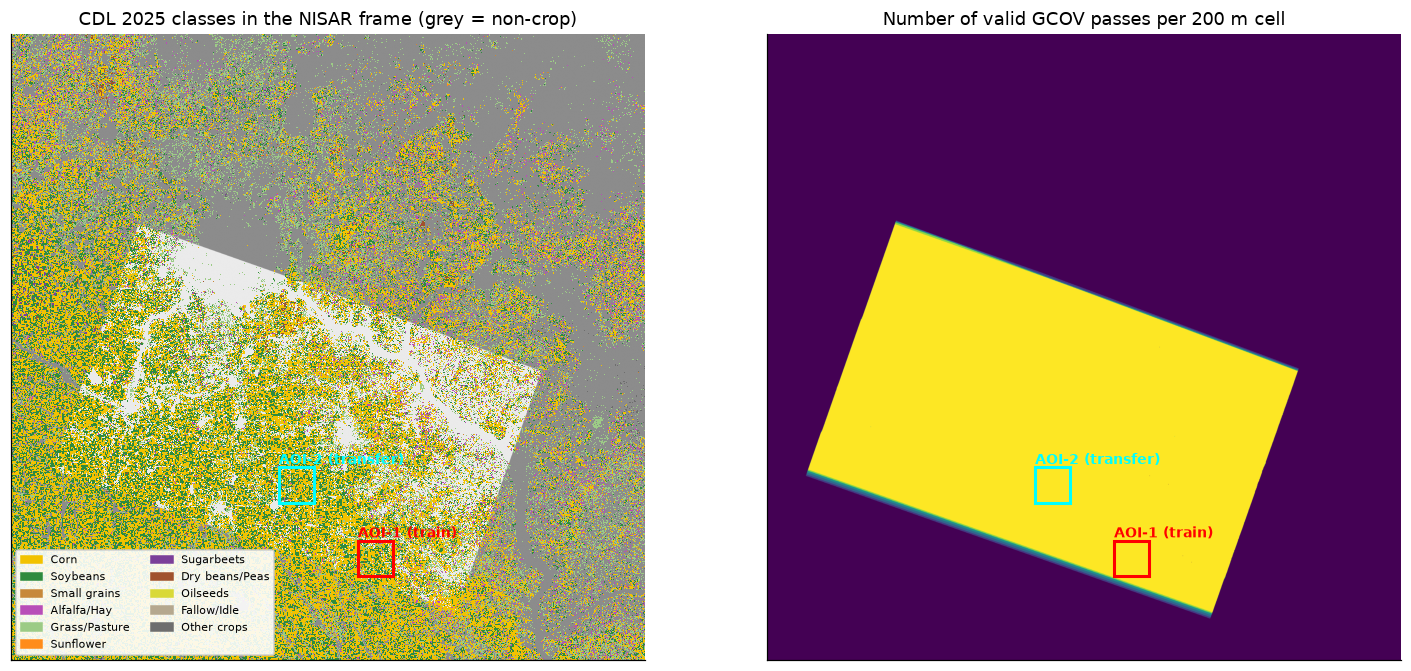

In [7]:
def choose_windows(grp, valid_all, size_cells, n=2):
    # Score square windows: cropland share x (0.5 + crop diversity), valid on all dates.
    ok = valid_all.astype(float)
    ag = ((grp != NONAG) & valid_all).astype(float)
    f_valid = ndi.uniform_filter(ok, size_cells, mode="constant")
    f_ag = ndi.uniform_filter(ag, size_cells, mode="constant")
    shares = [ndi.uniform_filter(((grp == k) & valid_all).astype(float), size_cells, mode="constant")
              for k in range(len(GROUP_NAMES))]
    with np.errstate(invalid="ignore", divide="ignore"):
        p = np.stack(shares) / np.where(f_ag > 0, f_ag, np.nan)
    diversity = 1 - np.nansum(p ** 2, 0)
    half = size_cells // 2                                   # centres whose window lies inside the grid
    inner = np.zeros_like(ok, bool)
    inner[half:ok.shape[0] - (size_cells - half), half:ok.shape[1] - (size_cells - half)] = True
    if not inner.any():
        raise ValueError("AOI_SIZE_KM is larger than the frame")
    need = MIN_VALID_FRAC
    if f_valid[inner].max() < need:                         # scattered flagged pixels everywhere: relax
        need = f_valid[inner].max() - 0.02
        print(f"No window is valid over {MIN_VALID_FRAC:.0%} of its area on all dates; using {need:.1%}")
    score = np.where(inner & (f_valid >= need), f_ag * (0.5 + diversity), -1)
    picks = []
    for _ in range(n):
        if score.max() <= 0:
            break
        r, c = np.unravel_index(np.argmax(score), score.shape)
        picks.append((r, c, float(f_ag[r, c]), float(diversity[r, c])))
        score[max(0, r - size_cells):r + size_cells, max(0, c - size_cells):c + size_cells] = -1
    return picks

SIZE_CELLS = int(round(AOI_SIZE_KM * 1000 / C_DX))
VALID_ALL = valid_count == len(stack)
picks = choose_windows(grp_coarse, VALID_ALL, SIZE_CELLS, n=2 if TRANSFER_AOI else 1)
if AOI_CENTER_LONLAT is not None:
    from pyproj import Transformer
    xc, yc = Transformer.from_crs(4326, STACK_CRS, always_xy=True).transform(*AOI_CENTER_LONLAT)
    col, row = ~COARSE_T * (xc, yc)
    picks[0] = (int(row), int(col), np.nan, np.nan)

N_PX = int(round(AOI_SIZE_KM * 1000 / POSTING))
def aoi_from_coarse(r, c, name):
    # Snap the AOI to the reference pixel grid (north-up row/col of the fine grid).
    r0 = int(r * S - N_PX // 2); c0 = int(c * S - N_PX // 2)
    r0 = int(np.clip(r0, 0, len(ref_y) - N_PX)); c0 = int(np.clip(c0, 0, len(ref_x) - N_PX))
    xs, ys = ref_x[c0:c0 + N_PX], ref_y[r0:r0 + N_PX]
    T = Affine(POSTING, 0, xs[0] - POSTING / 2, 0, -POSTING, ys[0] + POSTING / 2)
    bounds = (xs[0] - POSTING / 2, ys[-1] - POSTING / 2, xs[-1] + POSTING / 2, ys[0] + POSTING / 2)
    return {"name": name, "x": xs, "y": ys, "transform": T, "bounds": bounds, "shape": (N_PX, N_PX)}

AOIS = [aoi_from_coarse(p[0], p[1], name) for p, name in zip(picks, ["AOI-1 (train)", "AOI-2 (transfer)"])]
for a, p in zip(AOIS, picks):
    lo = transform_bounds(STACK_CRS, "EPSG:4326", *a["bounds"])
    print(f"{a['name']}: lon {lo[0]:.3f}..{lo[2]:.3f}, lat {lo[1]:.3f}..{lo[3]:.3f} | "
          f"cropland {p[2]:.0%}, diversity {p[3]:.2f}")

# Overview: dominant CDL class on the screening grid, invalid areas, and the chosen AOIs.
cmap_all = ListedColormap([GROUP_COLORS[n] for n in GROUP_NAMES])
fig, axes = plt.subplots(1, 2, figsize=(14, 6.2))
ext = [COARSE_T.c, COARSE_T.c + COARSE_SHAPE[1] * C_DX, COARSE_T.f - COARSE_SHAPE[0] * C_DX, COARSE_T.f]
show = np.ma.masked_where((grp_coarse == NONAG), grp_coarse)
axes[0].imshow(np.where(VALID_ALL, 0.92, 0.55), cmap="gray", vmin=0, vmax=1, extent=ext)
axes[0].imshow(show, cmap=cmap_all, vmin=0, vmax=len(GROUP_NAMES) - 1, extent=ext, interpolation="nearest")
axes[1].imshow(valid_count, cmap="viridis", vmin=0, vmax=len(stack), extent=ext)
for ax in axes:
    for a, col in zip(AOIS, ["red", "cyan"]):
        l, b, r, t = a["bounds"]
        ax.add_patch(Rectangle((l, b), r - l, t - b, fill=False, ec=col, lw=2))
        ax.text(l, t, a["name"], color=col, fontsize=9, va="bottom", fontweight="bold")
    ax.set_xticks([]); ax.set_yticks([])
axes[0].set_title(f"CDL {CDL_YEAR} classes in the NISAR frame (grey = non-crop)")
axes[1].set_title("Number of valid GCOV passes per 200 m cell")
axes[0].legend(handles=[Patch(color=GROUP_COLORS[n], label=n) for n in GROUP_NAMES],
               loc="lower left", fontsize=7, ncol=2, framealpha=0.9)
plt.tight_layout(); plt.savefig(OUT_DIR / "frame_overview.png", dpi=150); plt.show()

## Reading the AOI time series

For each pass, the AOI window is read straight from the HDF5 datasets (`HHHH`, `HVHV`, `mask`, `numberOfLooks`). These are the same paths GeoLattice `nisar.read_l2` uses (`/science/LSAR/GCOV/grids/frequencyA/...`); slicing the h5py dataset keeps memory at the AOI size. If a pass sits on a slightly different grid, it is resampled bilinearly onto the reference grid. Pixels outside the valid mask, or with γ⁰ ≤ 0, become NaN.

The result is an `xarray` cube `(time, pol, y, x)` of linear γ⁰ with the UTM CRS attached.


In [8]:
def read_gcov_window(path, bounds, pad_px=2):
    info = grid_info(path)
    l, b, r, t = bounds
    pad = pad_px * info["posting"]
    ix = np.flatnonzero((info["x"] >= l - pad) & (info["x"] <= r + pad))
    iy = np.flatnonzero((info["y"] >= b - pad) & (info["y"] <= t + pad))
    if ix.size == 0 or iy.size == 0:
        return None
    sl = (slice(iy.min(), iy.max() + 1), slice(ix.min(), ix.max() + 1))
    with h5py.File(path, "r") as f:
        g = f[GRID]
        data = [north_up(g[p][sl].astype(np.float32), info["dy"]) for p in POLS]
        mask = north_up(g["mask"][sl], info["dy"])
        looks = float(np.nanmedian(g["numberOfLooks"][sl])) if "numberOfLooks" in g else np.nan
    valid = mask_to_valid(mask)
    for a in data:
        valid &= np.isfinite(a) & (a > 0)
    data = np.stack([np.where(valid, a, np.nan) for a in data])
    xs = info["x"][ix]
    ys = info["y"][iy] if info["dy"] < 0 else info["y"][iy][::-1]
    T = Affine(info["posting"], 0, xs[0] - info["posting"] / 2, 0, -info["posting"], ys[0] + info["posting"] / 2)
    return data, T, info["crs"], looks

def load_aoi_stack(aoi):
    H, W = aoi["shape"]
    cube = np.full((len(stack), len(POLS), H, W), np.nan, np.float32)
    looks = []
    for t, s in enumerate(stack.itertuples()):
        out = read_gcov_window(s.file, aoi["bounds"])
        if out is None:
            print(f"  {s.time_utc:%Y-%m-%d}: no data in {aoi['name']}")
            continue
        data, T, crs, lk = out
        looks.append(lk)
        for k in range(len(POLS)):
            reproject(data[k], cube[t, k], src_transform=T, src_crs=crs, dst_transform=aoi["transform"],
                      dst_crs=STACK_CRS, resampling=Resampling.bilinear, src_nodata=np.nan, dst_nodata=np.nan)
    da = xr.DataArray(cube, dims=("time", "pol", "y", "x"),
                      coords={"time": DATES, "pol": ["HH", "HV"], "y": aoi["y"], "x": aoi["x"]},
                      name="gamma0", attrs={"units": "linear gamma0", "looks": float(np.nanmedian(looks))})
    return da.rio.write_crs(STACK_CRS)

t0 = time.time()
cubes = {}
for a in AOIS:
    cubes[a["name"]] = load_aoi_stack(a)
    c = cubes[a["name"]]
    print(f"{a['name']}: {dict(c.sizes)} | valid share per date "
          f"{np.round(np.isfinite(c.values).all(1).mean((1, 2)), 3).tolist()} | median looks {c.attrs['looks']:.1f}")
print(f"Read in {time.time() - t0:.0f}s")
AOI1 = AOIS[0]["name"]
cube_raw = cubes[AOI1]
cube_raw

AOI-1 (train): {'time': 6, 'pol': 2, 'y': 2000, 'x': 2000} | valid share per date [1.0, 1.0, 1.0, 1.0, 1.0, 1.0] | median looks 5.0


AOI-2 (transfer): {'time': 6, 'pol': 2, 'y': 2000, 'x': 2000} | valid share per date [1.0, 1.0, 1.0, 1.0, 1.0, 1.0] | median looks 4.8
Read in 4s


<xarray.DataArray 'gamma0' (time: 6, pol: 2, y: 2000, x: 2000)> Size: 192MB
array([[[[0.12514305, 0.0990324 , 0.12285805, ..., 0.14172935,
          0.1532917 , 0.34439468],
         [0.17487144, 0.33753967, 0.16730118, ..., 0.05772924,
          0.10160637, 0.05121899],
         [0.39186478, 0.21177483, 0.32564545, ..., 0.09455585,
          0.1285572 , 0.02594614],
         ...,
         [0.18737221, 0.33971405, 0.25501633, ..., 0.46327972,
          0.17684555, 0.1054306 ],
         [0.1365509 , 0.4322586 , 0.16905975, ..., 0.13520432,
          0.17979622, 0.20664215],
         [0.28134537, 0.2406578 , 0.16903496, ..., 0.22675705,
          0.49440002, 0.25899506]],

        [[0.02894211, 0.02314663, 0.02532649, ..., 0.0265069 ,
          0.014889  , 0.05771446],
         [0.02635026, 0.05889177, 0.03287792, ..., 0.01542318,
          0.01618934, 0.01640534],
         [0.04207373, 0.02704597, 0.02818131, ..., 0.0104723 ,
          0.01519632, 0.01244581],
...
          0.16628265, 0.5154877 ],
         [0.14249039, 0.11225414, 0.14317703, ..., 0.26951218,
          0.21092033, 0.19344139],
         [0.14915466, 0.22572517, 0.21678543, ..., 0.15787506,
          0.16337967, 0.5986557 ]],

        [[0.06244087, 0.05519247, 0.02140546, ..., 0.03327131,
          0.01833177, 0.02895308],
         [0.03428411, 0.02680182, 0.02107191, ..., 0.01968026,
          0.01229417, 0.02131701],
         [0.03051305, 0.01563883, 0.02050471, ..., 0.01197672,
          0.01983023, 0.00461781],
         ...,
         [0.01908588, 0.01809478, 0.0238297 , ..., 0.01647639,
          0.01728487, 0.02086091],
         [0.00971103, 0.0192492 , 0.01783514, ..., 0.02125072,
          0.02124453, 0.01609945],
         [0.01318288, 0.02433491, 0.02387118, ..., 0.00715941,
          0.01433206, 0.02338362]]]],
      shape=(6, 2, 2000, 2000), dtype=float32)
Coordinates:
  * time         (time) datetime64[us] 48B 2026-07-23 2026-08-16 ... 2026-10-15
  * pol          (pol) <U2 16B 'HH' 'HV'
  * y            (y) float64 16kB 4.815e+06 4.815e+06 ... 4.795e+06 4.795e+06
  * x            (x) float64 16kB 5.487e+05 5.487e+05 ... 5.687e+05 5.687e+05
    spatial_ref  int64 8B 0
Attributes:
    units:    linear gamma0
    looks:    5.0393288135528564

## Speckle filtering and dual-pol features

GCOV pixels at 10 m carry only a few looks (`numberOfLooks`), so single-date speckle is strong. The **Quegan & Yu (2001) multi-temporal filter** in GeoLattice (`speckle.multitemporal`) averages speckle across the six dates while each date keeps its own local mean, so the temporal signal is preserved and spatial blurring is small. The ENL is set from the median `numberOfLooks` of the window.

Features per date, from the filtered linear γ⁰:

| Channel | Definition |
|---|---|
| HH, HV | 10·log10(γ⁰) |
| HV − HH | cross-pol ratio (dB); rises with canopy volume |
| RVI | 4·HV / (HH + HV), dual-pol Radar Vegetation Index (`nisar.gcov_indices`) |


Filtered 2 AOI stacks in 4s: Quegan multi-temporal (lee, 5x5, ENL 5.0)
<xarray.Dataset> Size: 32MB
Dimensions:       (y: 2000, x: 2000)
Coordinates:
  * y             (y) float64 16kB 4.815e+06 4.815e+06 ... 4.795e+06 4.795e+06
  * x             (x) float64 16kB 5.487e+05 5.487e+05 ... 5.687e+05 5.687e+05
    time          datetime64[us] 8B 2026-08-16
    spatial_ref   int64 8B 0
    pol           <U2 8B 'HV'
Data variables:
    hv_hh_ratio   (y, x) float32 16MB 0.1806 0.2386 0.1366 ... 0.1149 0.141
    dual_pol_rvi  (y, x) float32 16MB 0.612 0.7705 0.4808 ... 0.4124 0.4942
Attributes:
    input_units:        linear gamma0
    min_power:          0.0
    polarization_mode:  dual


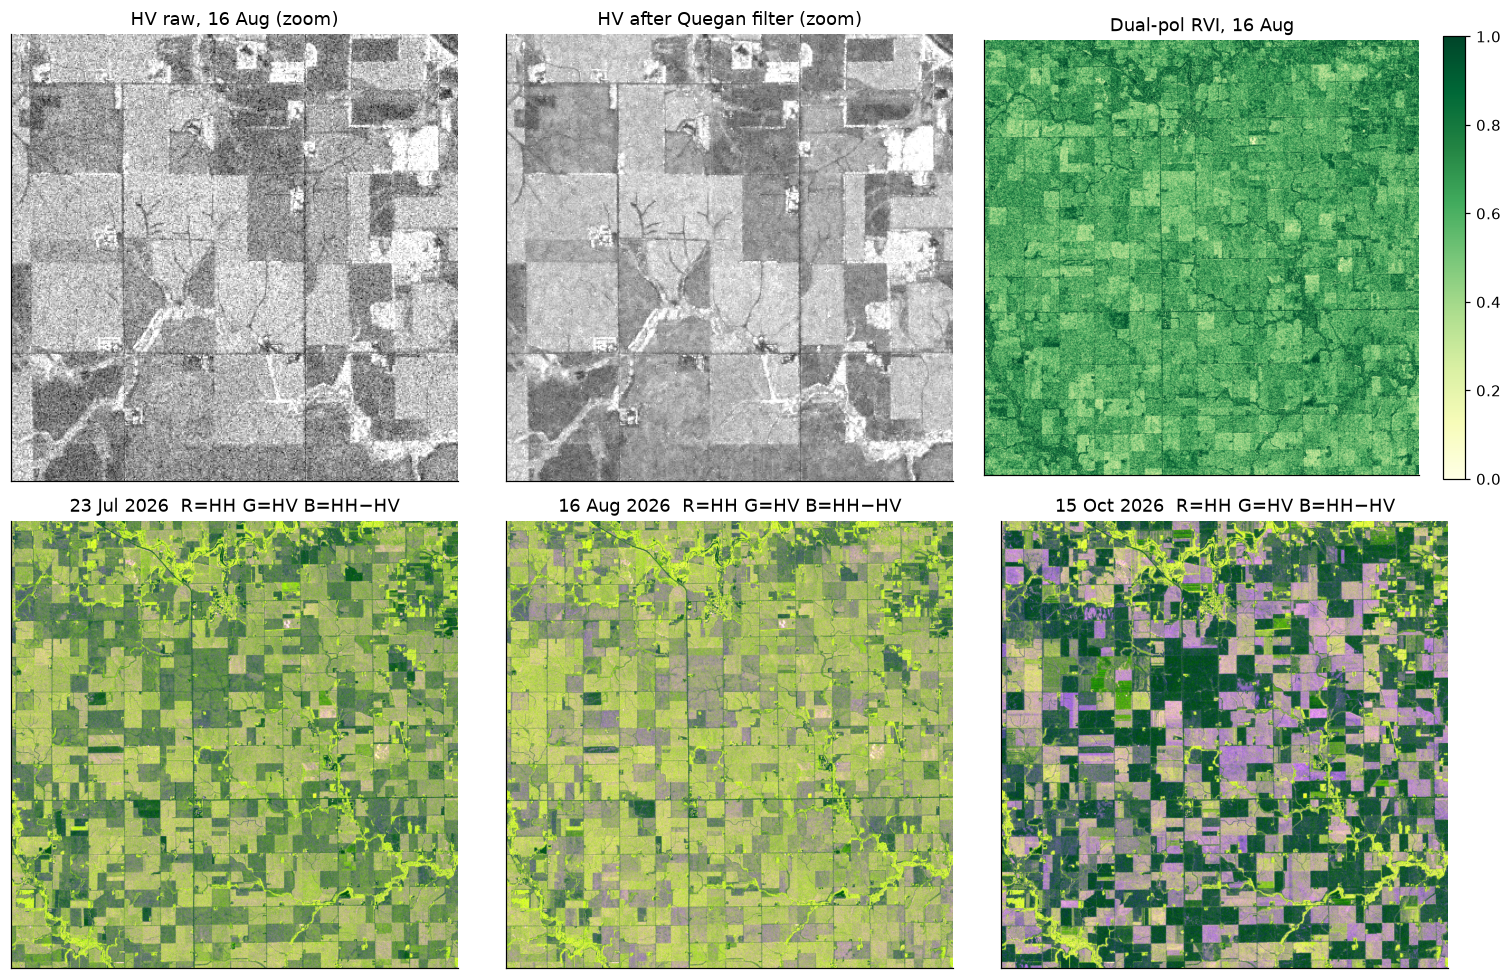

In [9]:
def filter_cube(c):
    out = c.copy()
    enl = max(1.0, float(c.attrs.get("looks", 4.0)))
    for k in range(c.sizes["pol"]):
        out.values[:, k] = np.asarray(speckle.multitemporal(c.values[:, k], spatial=SPECKLE_SPATIAL,
                                                            size=SPECKLE_SIZE, enl=enl, time_axis=0))
    out.attrs["speckle_filter"] = f"Quegan multi-temporal ({SPECKLE_SPATIAL}, {SPECKLE_SIZE}x{SPECKLE_SIZE}, ENL {enl:.1f})"
    return out

t0 = time.time()
cubes_f = {name: filter_cube(c) for name, c in cubes.items()}
print(f"Filtered {len(cubes_f)} AOI stacks in {time.time() - t0:.0f}s:", cubes_f[AOI1].attrs["speckle_filter"])
cube = cubes_f[AOI1]

# Dual-pol indices with GeoLattice for one mid-season date (used for the maps below).
mid = int(np.argmin(np.abs(DOYS - 230)))
idx_mid = nisar.gcov_indices(cube.isel(time=mid).sel(pol="HH"), cube.isel(time=mid).sel(pol="HV"))
print(idx_mid)

def stretch(a, lo, hi):
    return np.clip((a - lo) / (hi - lo), 0, 1)

def dual_rgb(c_t):
    # R = HH, G = HV, B = HH - HV (dB): bright green = volume scattering, magenta = bare/rough soil.
    hh, hv = to_db(c_t.sel(pol="HH").values), to_db(c_t.sel(pol="HV").values)
    rgb = np.dstack([stretch(hh, -18, -2), stretch(hv, -28, -10), stretch(hh - hv, 3, 14)])
    rgb[~np.isfinite(rgb)] = 1
    return rgb

win = (slice(0, 400), slice(0, 400))                         # 4 x 4 km zoom
fig, axes = plt.subplots(2, 3, figsize=(14, 9))
axes[0, 0].imshow(to_db(cubes[AOI1].isel(time=mid).sel(pol="HV").values)[win], cmap="gray", vmin=-28, vmax=-10)
axes[0, 0].set_title(f"HV raw, {DATES[mid]:%d %b} (zoom)")
axes[0, 1].imshow(to_db(cube.isel(time=mid).sel(pol="HV").values)[win], cmap="gray", vmin=-28, vmax=-10)
axes[0, 1].set_title("HV after Quegan filter (zoom)")
im = axes[0, 2].imshow(idx_mid["dual_pol_rvi"].values, cmap="YlGn", vmin=0, vmax=1)
axes[0, 2].set_title(f"Dual-pol RVI, {DATES[mid]:%d %b}"); plt.colorbar(im, ax=axes[0, 2], fraction=0.046)
for ax, t in zip(axes[1], [0, mid, len(DATES) - 1]):
    ax.imshow(dual_rgb(cube.isel(time=t))); ax.set_title(f"{DATES[t]:%d %b %Y}  R=HH G=HV B=HH−HV")
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.savefig(OUT_DIR / "aoi1_quicklooks.png", dpi=130); plt.show()

## The 10 m CDL on the NISAR grid

The CDL is warped (nearest neighbour) from CONUS Albers to the NISAR UTM grid of each AOI. Both are 10 m, so this is a near one-to-one resampling. CDL codes are then grouped into the crop classes defined in Section 1; rare classes in AOI-1 merge into *Other crops*, and if *Other crops* itself is rare, its pixels are left out.


In [10]:
def read_cdl_on_grid(aoi):
    out = np.zeros(aoi["shape"], np.uint8)
    with rasterio.open(CDL_PATH) as src:
        reproject(rasterio.band(src, 1), out, dst_transform=aoi["transform"], dst_crs=STACK_CRS,
                  resampling=Resampling.nearest, src_nodata=0, dst_nodata=0)
    return out

cdl_codes = {a["name"]: read_cdl_on_grid(a) for a in AOIS}

# Class list from AOI-1 cropland.
g1 = LUT_ALL[cdl_codes[AOI1]]
share = pd.Series(np.bincount(g1[g1 != NONAG], minlength=len(GROUP_NAMES)), index=GROUP_NAMES)
share = share / share.sum()
keep = [n for n in GROUP_NAMES[:-1] if share[n] >= MIN_CLASS_FRAC]
other_share = share.drop(keep).sum()
CLASSES = keep + (["Other crops"] if other_share >= MIN_CLASS_FRAC else [])
COLORS = [GROUP_COLORS[n] for n in CLASSES]
CMAP = ListedColormap(COLORS)
HANDLES = [Patch(color=c, label=n) for n, c in zip(CLASSES, COLORS)]

# Final lookup: CDL code -> class index (0..K-1), -1 = not analysed.
LUT = np.full(256, -1, np.int16)
for code_ in range(256):
    g = LUT_ALL[code_]
    if g == NONAG:
        continue
    name = GROUP_NAMES[g]
    if name in CLASSES:
        LUT[code_] = CLASSES.index(name)
    elif "Other crops" in CLASSES:
        LUT[code_] = CLASSES.index("Other crops")

print("Class shares of AOI-1 cropland:")
display((share.rename("share").to_frame().assign(kept=lambda d: d.index.isin(CLASSES))).round(3))
print("Classes used:", CLASSES)

# Most frequent original CDL codes in AOI-1 (what the groups contain here).
vals, cnts = np.unique(cdl_codes[AOI1], return_counts=True)
top = pd.DataFrame({"code": vals, "name": [CDL_NAMES.get(int(v), "?") for v in vals], "pixels": cnts,
                    "class": [CLASSES[LUT[v]] if LUT[v] >= 0 else "(masked)" for v in vals]})
display(top.sort_values("pixels", ascending=False).head(15).assign(share=lambda d: (d.pixels / d.pixels.sum()).round(3)))

Class shares of AOI-1 cropland:


,share,kept
Corn,0.482,True
Soybeans,0.341,True
Small grains,0.009,False
Alfalfa/Hay,0.024,True
Grass/Pasture,0.141,True
Sunflower,0.000,False
Sugarbeets,0.000,False
Dry beans/Peas,0.001,False
Oilseeds,0.000,False
Fallow/Idle,0.000,False


Classes used: ['Corn', 'Soybeans', 'Alfalfa/Hay', 'Grass/Pasture']


,code,name,pixels,class,share
0,1,Corn,1745334,Corn,0.440
2,5,Soybeans,1234789,Soybeans,0.311
32,176,Grassland/Pasture,507034,Grass/Pasture,0.128
28,141,Deciduous Forest,94142,(masked),0.024
24,122,Developed/Low Intensity,89741,(masked),0.023
23,121,Developed/Open Space,86996,(masked),0.022
12,36,Alfalfa,61823,Alfalfa/Hay,0.016
34,195,Herbaceous Wetlands,31398,(masked),0.008
10,28,Oats,28175,(masked),0.007
13,37,Other Hay/Non Alfalfa,26024,Alfalfa/Hay,0.007


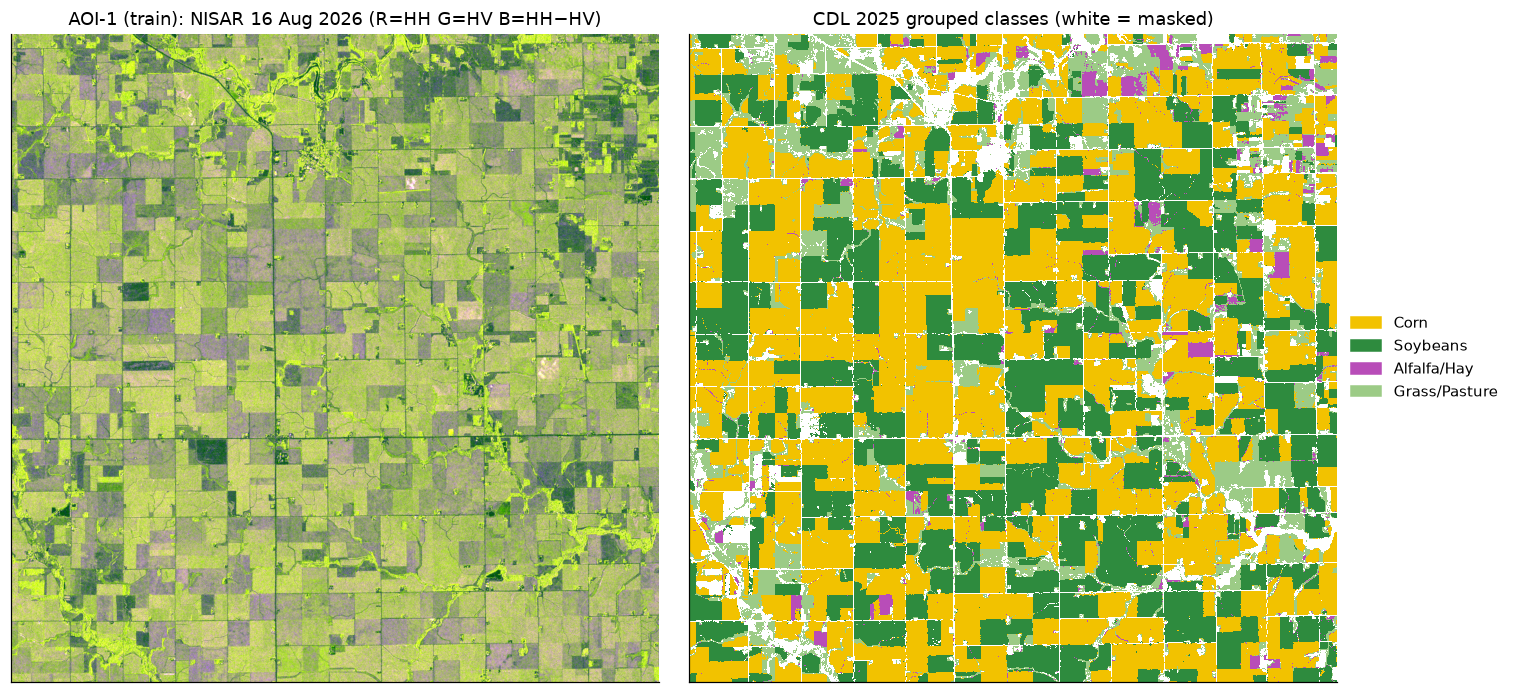

In [11]:
y_maps = {name: LUT[c] for name, c in cdl_codes.items()}
fig, axes = plt.subplots(1, 2, figsize=(14, 6.4))
axes[0].imshow(dual_rgb(cube.isel(time=mid)))
axes[0].set_title(f"{AOI1}: NISAR {DATES[mid]:%d %b %Y} (R=HH G=HV B=HH−HV)")
axes[1].imshow(np.ma.masked_less(y_maps[AOI1], 0), cmap=CMAP, vmin=0, vmax=len(CLASSES) - 1, interpolation="nearest")
axes[1].set_title(f"CDL {CDL_YEAR} grouped classes (white = masked)")
axes[1].legend(handles=HANDLES, loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False)
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.savefig(OUT_DIR / "aoi1_nisar_vs_cdl.png", dpi=130); plt.show()

### Class temporal signatures

Median backscatter per CDL class (interquartile range shaded), from the filtered stack. Late July is near peak canopy for corn and soybean; by mid-October most row crops are harvested or senescent. Small grains are already harvested (stubble) at the first date, which makes them low and flat. Corn has the highest HV volume scattering; soybean is close in HH but lower in HV and drops earlier.


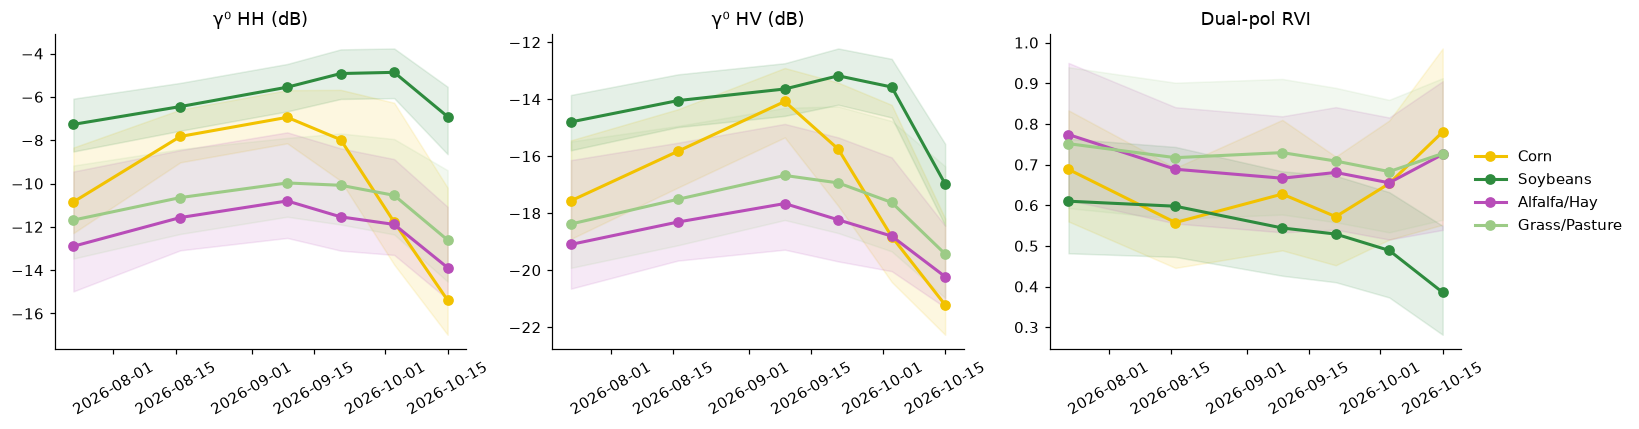

In [12]:
db = to_db(cube.values)                                         # (T, 2, H, W)
lin = cube.values
rvi = 4 * lin[:, 1] / (lin[:, 0] + lin[:, 1])
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True)
ym = y_maps[AOI1]
rng_sig = np.random.default_rng(SEED)
for c, name in enumerate(CLASSES):
    pix = np.flatnonzero(ym.ravel() == c)
    pix = rng_sig.choice(pix, min(len(pix), 50_000), replace=False)
    for ax, series, title in zip(axes, [db[:, 0].reshape(len(DATES), -1)[:, pix],
                                        db[:, 1].reshape(len(DATES), -1)[:, pix],
                                        rvi.reshape(len(DATES), -1)[:, pix]],
                                 ["γ⁰ HH (dB)", "γ⁰ HV (dB)", "Dual-pol RVI"]):
        med = np.nanmedian(series, 1)
        q1, q3 = np.nanpercentile(series, [25, 75], axis=1)
        ax.plot(DATES, med, "o-", color=COLORS[c], lw=2, label=name)
        ax.fill_between(DATES, q1, q3, color=COLORS[c], alpha=0.12)
        ax.set_title(title)
for ax in axes:
    ax.tick_params(axis="x", rotation=30)
axes[2].legend(loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False)
plt.tight_layout(); plt.savefig(OUT_DIR / "class_signatures.png", dpi=130); plt.show()

## Field-like units and spatially blocked splits

The CDL has no parcel boundaries, but neighbouring pixels in one field are strongly correlated, so random pixel splits leak information and inflate accuracy. Field-like units are built from the CDL itself:

1. **Interior pixels**: pixels whose 3 × 3 neighbourhood is all the same class (drops mixed boundary pixels, roads, shelterbelts)
2. **Connected components** of interior pixels per class, cut at a 1 km grid so large contiguous patches become several units
3. Units smaller than 0.5 ha are dropped

Whole **2 km blocks** go to train, validation or test. The 1 km cutting grid nests inside the 2 km blocks, so no unit straddles two splits. Training labels come only from interior pixels of training units; the wall-to-wall validation in Section 12 uses *every* cropland pixel of the test blocks, boundaries included.

Label budgets are counted in **labeled fields per class** (1, 5, 20, all), mimicking a survey that visits a handful of fields per crop.


2,394 field-like units in AOI-1 (train) (median 566 px = 5.7 ha). Units per class and split:


split,test,train,val
Corn,308,499,144
Soybeans,210,408,107
Alfalfa/Hay,30,61,18
Grass/Pasture,175,324,110


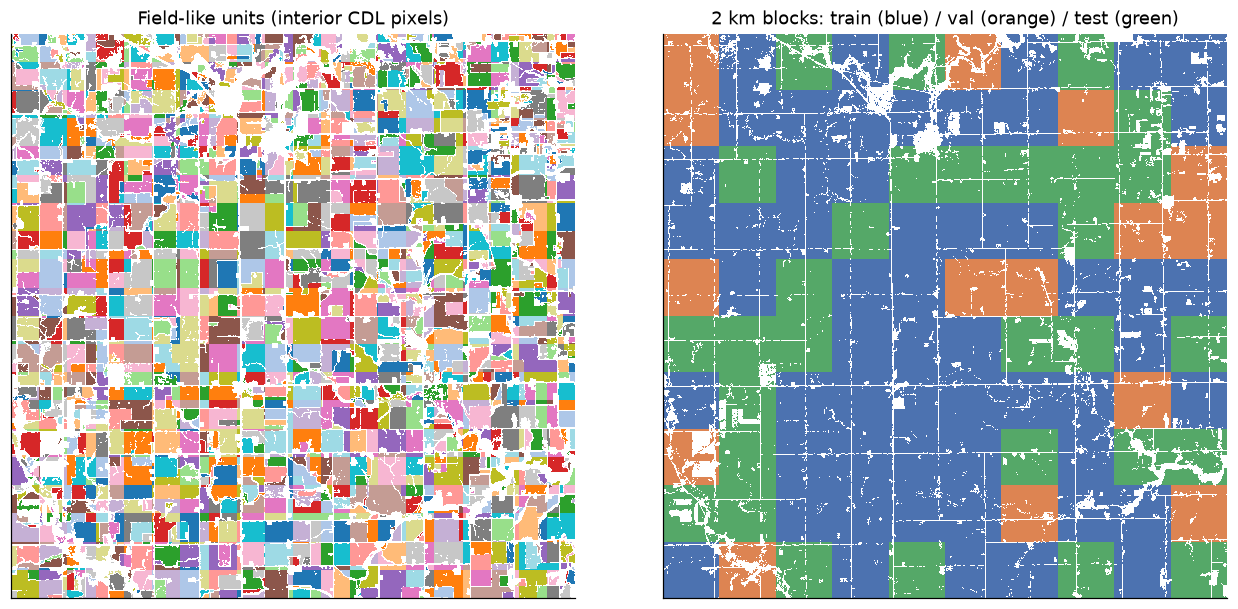

In [13]:
def make_units(ym):
    H, W = ym.shape
    interior = (ndi.maximum_filter(ym, 3) == ndi.minimum_filter(ym, 3)) & (ym >= 0)
    tile_px = int(FIELD_TILE_M / POSTING)
    rr, cc = np.indices((H, W))
    n_tc = int(np.ceil(W / tile_px))
    tile = (rr // tile_px) * n_tc + (cc // tile_px)
    fid = np.full((H, W), -1, np.int64)
    offset = 0
    for c in range(len(CLASSES)):
        lab, n = ndi.label(interior & (ym == c))
        on = lab > 0
        key = lab[on].astype(np.int64) * (tile.max() + 1) + tile[on]
        _, inv = np.unique(key, return_inverse=True)
        fid[on] = inv.ravel() + offset
        offset += inv.max() + 1 if inv.size else 0
    sizes = np.bincount(fid[fid >= 0])
    fid[(fid >= 0) & (sizes[np.clip(fid, 0, None)] < MIN_FIELD_PX)] = -1
    _, fid_c = np.unique(fid.ravel(), return_inverse=True)        # compact ids, -1 stays smallest
    fid = fid_c.reshape(H, W) - (1 if (fid < 0).any() else 0)
    block_px = int(BLOCK_M / POSTING)
    n_bc = int(np.ceil(W / block_px))
    block = (rr // block_px) * n_bc + (cc // block_px)
    return fid, block

def block_splits(block, seed=SEED):
    rng = np.random.default_rng(seed)
    ids = np.unique(block)
    rng.shuffle(ids)
    n_test = int(round(SPLIT_FRACTIONS["test"] * len(ids)))
    n_val = int(round(SPLIT_FRACTIONS["val"] * len(ids)))
    names = np.array(["test"] * n_test + ["val"] * n_val + ["train"] * (len(ids) - n_test - n_val))
    order = np.argsort(ids)
    return names[order][np.searchsorted(ids[order], block)]

field_maps, split_maps = {}, {}
for a in AOIS:
    fid, block = make_units(y_maps[a["name"]])
    field_maps[a["name"]] = fid
    split_maps[a["name"]] = block_splits(block) if a["name"] == AOI1 else np.full(block.shape, "test")

fid1, split1 = field_maps[AOI1], split_maps[AOI1]
units = pd.DataFrame({"field": fid1[fid1 >= 0], "y": y_maps[AOI1][fid1 >= 0], "split": split1[fid1 >= 0]})
fields_tab = units.groupby("field").agg(y=("y", "first"), split=("split", "first"), n=("y", "size"))
summary = fields_tab.groupby(["y", "split"]).size().unstack().fillna(0).astype(int)
summary.index = [CLASSES[i] for i in summary.index]
print(f"{len(fields_tab):,} field-like units in {AOI1} (median {fields_tab.n.median():.0f} px = "
      f"{fields_tab.n.median() * POSTING**2 / 1e4:.1f} ha). Units per class and split:")
display(summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.6))
rng_c = np.random.default_rng(0)
perm = rng_c.permutation(fid1.max() + 2)
axes[0].imshow(np.ma.masked_less(perm[fid1 + 1] * (fid1 >= 0), 1), cmap="tab20", interpolation="nearest")
axes[0].set_title("Field-like units (interior CDL pixels)")
code_split = np.select([split1 == "train", split1 == "val", split1 == "test"], [0, 1, 2])
axes[1].imshow(np.ma.masked_where(y_maps[AOI1] < 0, code_split),
               cmap=ListedColormap(["#4C72B0", "#DD8452", "#55A868"]), interpolation="nearest")
axes[1].set_title("2 km blocks: train (blue) / val (orange) / test (green)")
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

## Pixel time series and the Random Forest baseline

Every cropland pixel with at least `MIN_VALID_DATES` valid passes becomes one sample:

- `x_db` (T, 2): filtered HH and HV in dB (0 where invalid)
- `doy` (T,): acquisition day of year
- `valid` (T,): True where the pass was valid

The baseline is the standard approach before deep learning: fill gaps by linear interpolation in time, then use the per-date values plus seasonal statistics of each channel (mean, standard deviation, minimum, maximum and the DOY of the maximum) in a Random Forest.


In [14]:
def pixel_samples(name):
    c = cubes_f[name]
    ym, fid, split = y_maps[name], field_maps[name], split_maps[name]
    x_db = np.moveaxis(to_db(c.values), (0, 1), (2, 3))          # (H, W, T, 2)
    valid = np.isfinite(x_db).all(-1)
    use = (ym >= 0) & (valid.sum(-1) >= MIN_VALID_DATES)
    rows, cols = np.nonzero(use)
    X = np.nan_to_num(x_db[rows, cols], nan=0.0).astype(np.float32)
    V = valid[rows, cols]
    D = np.tile(DOYS, (len(rows), 1)).astype(np.float32)
    meta = pd.DataFrame({"row": rows, "col": cols, "y": ym[rows, cols], "field": fid[rows, cols],
                         "split": split[rows, cols]})
    return X, D, V, meta

t0 = time.time()
samples = {a["name"]: pixel_samples(a["name"]) for a in AOIS}
xA, dA, vA, metaA = samples[AOI1]
yA = metaA.y.values
for name, (X, D, V, m) in samples.items():
    print(f"{name}: {len(X):,} cropland pixels, {X.shape[1]} dates, valid observations {V.mean():.3f}")
print(f"({time.time() - t0:.0f}s)")

CHANNELS = ["HH", "HV", "HV-HH", "RVI"]

def raw_features_np(x_db):
    lin = 10 ** (x_db / 10)
    hh, hv = x_db[..., 0], x_db[..., 1]
    rvi = 4 * lin[..., 1] / (lin[..., 0] + lin[..., 1] + 1e-8)
    return np.stack([hh, hv, hv - hh, rvi], -1)

def fill_time(v, valid, doy):
    # Linear interpolation over time for each pixel (vectorised; edges take the nearest valid value).
    N, T = v.shape
    t = np.arange(T)
    prev = np.maximum.accumulate(np.where(valid, t, -1), axis=1)
    nxt = np.minimum.accumulate(np.where(valid, t, T)[:, ::-1], axis=1)[:, ::-1]
    p, n = np.clip(prev, 0, T - 1), np.clip(nxt, 0, T - 1)
    vp, vn = np.take_along_axis(v, p, 1), np.take_along_axis(v, n, 1)
    dp, dn = np.take_along_axis(doy, p, 1), np.take_along_axis(doy, n, 1)
    w = np.where(dn > dp, (doy - dp) / np.where(dn > dp, dn - dp, 1), 0)
    out = np.where(prev < 0, vn, np.where(nxt >= T, vp, vp + w * (vn - vp)))
    return np.where(valid, v, out)

def handcrafted(x_db, doy, valid):
    f = raw_features_np(x_db)
    feats = []
    for c in range(f.shape[-1]):
        v = np.where(valid, f[..., c], np.nan)
        filled = fill_time(np.nan_to_num(v), valid, doy)
        imax = np.argmax(np.where(valid, v, -np.inf), 1)
        feats += [filled, np.nanmean(v, 1)[:, None], np.nanstd(v, 1)[:, None], np.nanmin(v, 1)[:, None],
                  np.nanmax(v, 1)[:, None], doy[np.arange(len(v)), imax][:, None]]
    return np.concatenate(feats, 1).astype(np.float32)

t0 = time.time()
HF = {name: handcrafted(X, D, V) for name, (X, D, V, m) in samples.items()}
HF_A = HF[AOI1]
print("Handcrafted features:", HF_A.shape, f"({time.time() - t0:.0f}s)")

AOI-1 (train): 3,580,797 cropland pixels, 6 dates, valid observations 1.000
AOI-2 (transfer): 3,587,550 cropland pixels, 6 dates, valid observations 1.000
(2s)


Handcrafted features: (3580797, 44) (16s)


In [15]:
rng = np.random.default_rng(SEED)
idx_val = np.flatnonzero((metaA.split == "val") & (metaA.field >= 0))
idx_val = rng.choice(idx_val, min(VAL_SAMPLE, len(idx_val)), replace=False)
idx_test_int = np.flatnonzero((metaA.split == "test") & (metaA.field >= 0))     # interior test pixels
idx_eval = rng.choice(idx_test_int, min(EVAL_SAMPLE, len(idx_test_int)), replace=False)

def sample_label_budget(meta, n_per_class, seed):
    # n labeled training units per class -> pixel indices (capped per class).
    r = np.random.default_rng(seed)
    tr = meta[(meta.split == "train") & (meta.field >= 0)]
    idx = []
    for c in range(len(CLASSES)):
        fl = tr.loc[tr.y == c, "field"].unique()
        if len(fl) == 0:
            continue
        k = len(fl) if n_per_class == "all" else min(n_per_class, len(fl))
        chosen = r.choice(fl, k, replace=False)
        pix = tr.index[tr.field.isin(chosen) & (tr.y == c)].values
        idx.append(r.choice(pix, min(len(pix), MAX_PIX_PER_CLASS), replace=False))
    return np.concatenate(idx)

def evaluate(y_true, y_pred):
    return {"OA": accuracy_score(y_true, y_pred),
            "macroF1": f1_score(y_true, y_pred, average="macro", labels=np.unique(y_true)),
            "kappa": cohen_kappa_score(y_true, y_pred)}

results, rf_models = [], {}
t0 = time.time()
for budget in BUDGETS:
    for s in SEEDS:
        idx = sample_label_budget(metaA, budget, seed=100 + s)
        rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=2, n_jobs=-1,
                                    class_weight="balanced", random_state=s).fit(HF_A[idx], yA[idx])
        r = evaluate(yA[idx_eval], rf.predict(HF_A[idx_eval]))
        results.append({"method": "Random Forest", "budget": str(budget), "seed": s, "n_pixels": len(idx), **r})
        if s == 0:
            rf_models[str(budget)] = rf
print(f"Random Forest: {time.time() - t0:.0f}s")
pd.DataFrame(results).groupby(["method", "budget"], sort=False)[["n_pixels", "OA", "macroF1", "kappa"]].mean().round(3)

Random Forest: 12s


n_pixels     OA  macroF1  kappa
method        budget                                 
Random Forest 1         2126.5  0.674    0.535  0.501
              5        14620.0  0.701    0.550  0.518
              20       20000.0  0.730    0.603  0.570
              all      20000.0  0.781    0.664  0.641

## Transformer encoder for SAR time series

Each acquisition is a token:

```
x_db (T × 2) ──Featurizer──> (T × 4: HH, HV, HV−HH, RVI) ──Linear──> (T × d) + DOY encoding
        ──> Transformer encoder (attention ignores invalid dates) ──> (T × d) ──mean over valid dates──> embedding
```

- **DOY positional encoding** on the real acquisition day, so the 24-day gaps (16 Aug, 9 Sep) and any missing pass are handled without gap filling.
- **Key padding mask**: invalid dates are ignored by attention.
- The **Featurizer** computes the ratio and RVI inside PyTorch with the same formulas as `nisar.gcov_indices`, so the SimCLR augmentations can perturb HH and HV first and keep the derived channels consistent.

Normalization statistics come from the unlabeled pool.


In [16]:
class Featurizer(nn.Module):
    # dB backscatter (B, T, 2) -> normalised 4-channel features (B, T, 4)
    def __init__(self, mean=None, std=None):
        super().__init__()
        self.register_buffer("mean", torch.zeros(4) if mean is None else torch.as_tensor(mean, dtype=torch.float32))
        self.register_buffer("std", torch.ones(4) if std is None else torch.as_tensor(std, dtype=torch.float32))

    @staticmethod
    def raw(x_db):
        hh, hv = x_db[..., 0], x_db[..., 1]
        lin = 10 ** (x_db / 10)
        rvi = 4 * lin[..., 1] / (lin[..., 0] + lin[..., 1] + 1e-8)
        return torch.stack([hh, hv, hv - hh, rvi], -1)

    def forward(self, x_db, valid):
        f = (self.raw(x_db) - self.mean) / self.std
        return torch.where(valid.unsqueeze(-1), f, torch.zeros_like(f))

# Unlabeled pool: random pixels from BOTH AOIs (no labels used).
rng = np.random.default_rng(SEED)
pool = []
for name, (X, D, V, m) in samples.items():
    k = min(len(X), SSL_POOL // len(samples))
    sel = rng.choice(len(X), k, replace=False)
    pool.append((X[sel], D[sel], V[sel]))
XU = np.concatenate([p[0] for p in pool]); DU = np.concatenate([p[1] for p in pool]); VU = np.concatenate([p[2] for p in pool])
with torch.no_grad():
    raw = Featurizer.raw(torch.from_numpy(XU))[torch.from_numpy(VU)]
    FEAT_MEAN, FEAT_STD = raw.mean(0), raw.std(0)
print(f"Unlabeled pool: {len(XU):,} pixel time series from {len(samples)} AOI(s)")
display(pd.DataFrame({"mean": FEAT_MEAN.numpy(), "std": FEAT_STD.numpy()}, index=CHANNELS).round(3))

def doy_encoding(doy, d_model, max_period=366.0):
    half = d_model // 2
    freqs = torch.exp(-torch.arange(half, device=doy.device) * np.log(1000.0) / half)
    ang = doy.unsqueeze(-1) / max_period * 2 * np.pi * freqs * 60
    return torch.cat([ang.sin(), ang.cos()], -1)

class TSEncoder(nn.Module):
    def __init__(self, n_ch=4, d_model=64, n_layers=3, n_heads=4, dropout=0.1):
        super().__init__()
        self.featurizer = Featurizer(FEAT_MEAN, FEAT_STD)
        self.proj = nn.Linear(n_ch, d_model)
        self.mask_token = nn.Parameter(torch.zeros(1, 1, d_model))
        layer = nn.TransformerEncoderLayer(d_model, n_heads, 4 * d_model, dropout, batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(layer, n_layers, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(d_model)
        self.d_model = d_model

    def tokens(self, x_db, doy, valid, mae_mask=None):
        h = self.proj(self.featurizer(x_db, valid))
        if mae_mask is not None:
            h = torch.where(mae_mask.unsqueeze(-1), self.mask_token.expand_as(h), h)
        h = h + doy_encoding(doy, self.d_model)
        return self.norm(self.encoder(h, src_key_padding_mask=~valid))

    def forward(self, x_db, doy, valid):
        h = self.tokens(x_db, doy, valid)
        w = valid.unsqueeze(-1).float()
        return (h * w).sum(1) / w.sum(1).clamp(min=1)

def to_t(*arrs):
    return [torch.as_tensor(a).to(DEVICE) for a in arrs]

print(f"Encoder parameters: {sum(p.numel() for p in TSEncoder().parameters()):,}")

Unlabeled pool: 300,000 pixel time series from 2 AOI(s)


,mean,std
HH,-8.330000,3.743
HV,-16.033001,3.180
HV-HH,-7.704000,2.130
RVI,0.621000,0.250


Encoder parameters: 150,464


## Self-supervised pretraining

### Masked autoencoding (MAE)

For every pixel, half of its valid dates are replaced by a learned mask token and a small decoder reconstructs the four normalised features at those dates. With six dates this means predicting, say, the September HV of a pixel from its July, October and other values; the encoder has to learn how backscatter evolves through canopy closure, senescence and harvest. The loss is the mean squared error on masked dates only.


In [17]:
class TimeSeriesMAE(nn.Module):
    def __init__(self, mask_ratio=0.5, **kw):
        super().__init__()
        self.encoder = TSEncoder(**kw)
        self.decoder = nn.Sequential(nn.Linear(self.encoder.d_model, 64), nn.GELU(), nn.Linear(64, 4))
        self.mask_ratio = mask_ratio

    def forward(self, x_db, doy, valid):
        target = self.encoder.featurizer(x_db, valid)
        mae_mask = (torch.rand(valid.shape, device=valid.device) < self.mask_ratio) & valid
        keep_one = valid & ~mae_mask                           # never mask every valid date of a pixel
        none_left = keep_one.sum(1) == 0
        mae_mask[none_left] = False
        h = self.encoder.tokens(x_db, doy, valid, mae_mask)
        recon = self.decoder(h)
        loss = ((recon - target) ** 2).mean(-1)[mae_mask].mean()
        return loss, recon, mae_mask

def batches(n, bs, rng):
    idx = rng.permutation(n)
    for i in range(0, n - bs + 1, bs):
        yield idx[i:i + bs]

def pretrain(model, epochs, bs=1024, lr=1e-3, seed=SEED, label="MAE"):
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    model = model.to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.05)
    steps = epochs * (len(XU) // bs)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=steps, pct_start=0.1)
    hist = []
    for ep in range(epochs):
        model.train(); losses = []
        for b in batches(len(XU), bs, rng):
            x, d, v = to_t(XU[b], DU[b], VU[b])
            out = model(x, d, v)
            loss = out[0] if isinstance(out, tuple) else out
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); sched.step(); losses.append(loss.item())
        hist.append(float(np.mean(losses)))
        print(f"{label} epoch {ep + 1:2d}/{epochs}  loss {hist[-1]:.4f}")
    return model, hist

t0 = time.time()
mae, mae_hist = pretrain(TimeSeriesMAE(), MAE_EPOCHS, label="MAE")
print(f"MAE pretraining: {time.time() - t0:.0f}s")
torch.save(mae.encoder.state_dict(), OUT_DIR / "encoder_mae.pt")

MAE epoch  1/10  loss 0.5067


MAE epoch  2/10  loss 0.3309


MAE epoch  3/10  loss 0.3214


MAE epoch  4/10  loss 0.3174


MAE epoch  5/10  loss 0.3147


MAE epoch  6/10  loss 0.3127


MAE epoch  7/10  loss 0.3118


MAE epoch  8/10  loss 0.3109


MAE epoch  9/10  loss 0.3096


MAE epoch 10/10  loss 0.3103
MAE pretraining: 31s


**Did the encoder learn phenology?** A few AOI-1 test pixels per class with half their dates hidden. The model never saw a label; it reconstructs the hidden HV values (normalised units) from the remaining dates.


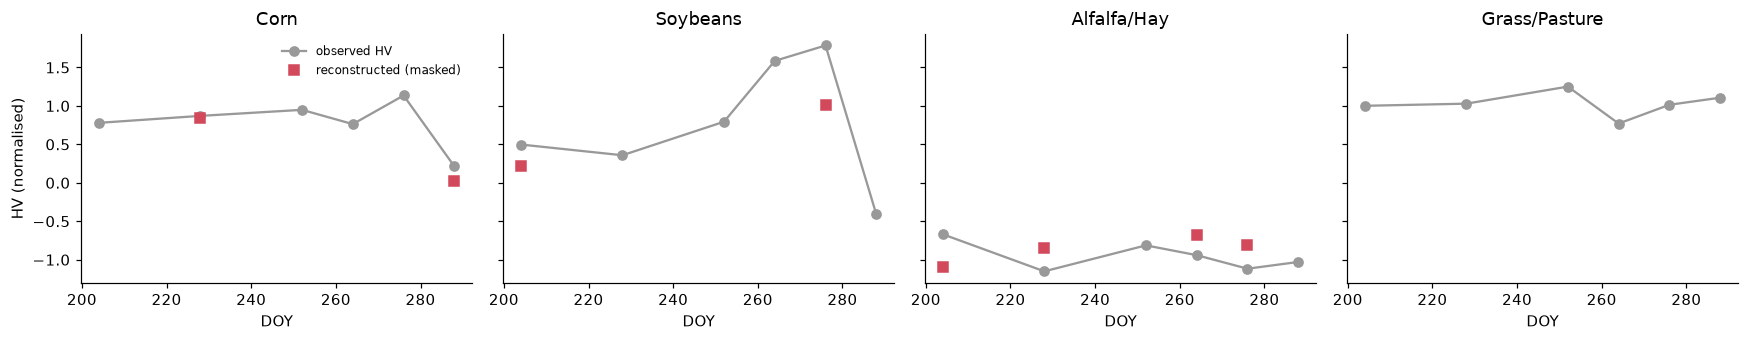

In [18]:
mae.eval()
torch.manual_seed(7)
show_classes = list(range(min(4, len(CLASSES))))
fig, axes = plt.subplots(1, len(show_classes), figsize=(4 * len(show_classes), 3.2), sharey=True)
for ax, c in zip(np.atleast_1d(axes), show_classes):
    cand = idx_test_int[(yA[idx_test_int] == c) & (vA[idx_test_int].sum(1) == len(DATES))]
    if len(cand) == 0:
        continue
    i = cand[len(cand) // 2]
    x, d, v = to_t(xA[i:i + 1], dA[i:i + 1], vA[i:i + 1])
    with torch.no_grad():
        _, recon, m = mae(x, d, v)
        tgt = mae.encoder.featurizer(x, v)
    dd, vv, mm = d[0].cpu().numpy(), v[0].cpu().numpy(), m[0].cpu().numpy()
    ax.plot(dd[vv], tgt[0, vv, 1].cpu(), "o-", color="0.6", label="observed HV")
    ax.plot(dd[mm], recon[0, mm, 1].cpu(), "s", color="#D1495B", ms=7, label="reconstructed (masked)")
    ax.set_title(CLASSES[c]); ax.set_xlabel("DOY")
np.atleast_1d(axes)[0].set_ylabel("HV (normalised)"); np.atleast_1d(axes)[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

### Contrastive learning (SimCLR) with SAR-specific augmentations

Two random views of each pixel are created and the encoder is trained so the two views of the same pixel have similar embeddings and differ from the other pixels in the batch (NT-Xent loss). Augmentations act on dB backscatter **before** featurisation:

| Augmentation | What it mimics |
|---|---|
| Date dropout (20%, at least 3 dates kept) | Missing passes, RFI-flagged dates |
| Multiplicative gamma speckle (L = 8) | Residual speckle after filtering |
| Gain shift (±0.5 dB per polarisation) | Calibration differences between passes or releases |
| DOY jitter (±6 days) | Field-to-field differences in planting and harvest dates |


SimCLR epoch  1/6  loss 5.4738


SimCLR epoch  2/6  loss 5.2116


SimCLR epoch  3/6  loss 5.1835


SimCLR epoch  4/6  loss 5.1666


SimCLR epoch  5/6  loss 5.1556


SimCLR epoch  6/6  loss 5.1478
SimCLR pretraining: 45s


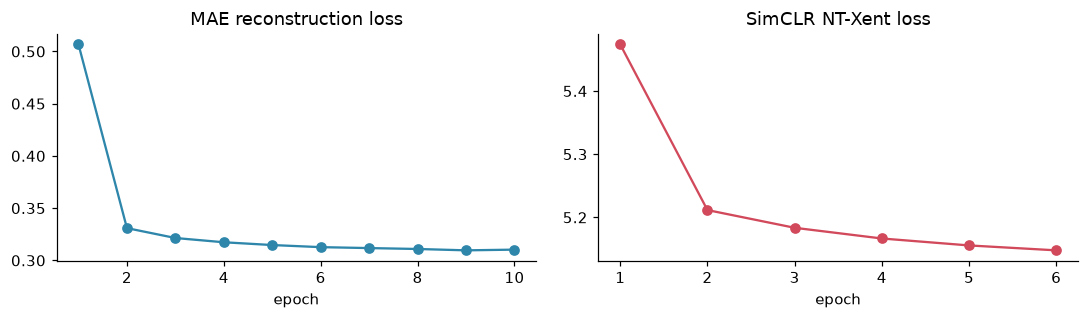

In [19]:
def sar_augment(x_db, doy, valid, p_drop=0.2, looks=8.0, gain_db=0.5, doy_jitter=6.0, min_keep=3):
    B, T, C = x_db.shape
    keep = valid & (torch.rand(B, T, device=x_db.device) > p_drop)
    few = keep.sum(1) < min_keep
    keep[few] = valid[few]
    lin = 10 ** (x_db / 10)
    spk = torch.distributions.Gamma(torch.tensor(looks), torch.tensor(looks)).sample(lin.shape).to(x_db.device)
    x = 10 * torch.log10(lin * spk + 1e-8)
    x = x + (torch.rand(B, 1, C, device=x_db.device) * 2 - 1) * gain_db
    d = doy + (torch.rand(B, 1, device=x_db.device) * 2 - 1) * doy_jitter
    return torch.where(keep.unsqueeze(-1), x, torch.zeros_like(x)), d, keep

class SimCLR(nn.Module):
    def __init__(self, tau=0.2, **kw):
        super().__init__()
        self.encoder = TSEncoder(**kw)
        d = self.encoder.d_model
        self.head = nn.Sequential(nn.Linear(d, d), nn.GELU(), nn.Linear(d, 32))
        self.tau = tau

    def forward(self, x_db, doy, valid):
        z = []
        for _ in range(2):
            xa, da, va = sar_augment(x_db, doy, valid)
            z.append(F.normalize(self.head(self.encoder(xa, da, va)), dim=-1))
        z = torch.cat(z)
        sim = z @ z.T / self.tau
        B = x_db.shape[0]
        sim.fill_diagonal_(-1e9)
        target = torch.cat([torch.arange(B, 2 * B), torch.arange(0, B)]).to(z.device)
        return F.cross_entropy(sim, target)

t0 = time.time()
simclr, simclr_hist = pretrain(SimCLR(), SIMCLR_EPOCHS, bs=512, label="SimCLR")
print(f"SimCLR pretraining: {time.time() - t0:.0f}s")
torch.save(simclr.encoder.state_dict(), OUT_DIR / "encoder_simclr.pt")

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].plot(range(1, len(mae_hist) + 1), mae_hist, "o-", color="#2E86AB"); axes[0].set_title("MAE reconstruction loss")
axes[1].plot(range(1, len(simclr_hist) + 1), simclr_hist, "o-", color="#D1495B"); axes[1].set_title("SimCLR NT-Xent loss")
for ax in axes:
    ax.set_xlabel("epoch")
plt.tight_layout(); plt.show()

## Fine-tuning, linear probing and label efficiency

| Variant | Encoder start | Encoder trained? |
|---|---|---|
| Scratch | random | yes |
| MAE probe | MAE weights | no (frozen) |
| MAE fine-tune | MAE weights | yes, 10× smaller learning rate |
| SimCLR probe | SimCLR weights | no |
| SimCLR fine-tune | SimCLR weights | yes, 10× smaller learning rate |

All runs use the same number of steps, class-balanced batches, light label smoothing and early stopping on validation macro-F1. Each budget is repeated with two random draws of labeled units. Methods are compared on the same 60,000 interior pixels of the test blocks.


In [20]:
class CropClassifier(nn.Module):
    def __init__(self, encoder, n_classes, linear=False):
        super().__init__()
        self.encoder = encoder
        d = encoder.d_model
        self.head = (nn.Linear(d, n_classes) if linear else
                     nn.Sequential(nn.LayerNorm(d), nn.Linear(d, 64), nn.GELU(), nn.Dropout(0.2), nn.Linear(64, n_classes)))

    def forward(self, x, d, v):
        return self.head(self.encoder(x, d, v))

def make_encoder(init):
    enc = TSEncoder()
    if init in ("mae", "simclr"):
        enc.load_state_dict(torch.load(OUT_DIR / f"encoder_{init}.pt", map_location="cpu"))
    return enc

@torch.no_grad()
def predict(model, X, D, V, bs=8192, return_emb=False):
    model.eval(); out = []
    for i in range(0, len(X), bs):
        x, d, v = to_t(X[i:i + bs], D[i:i + bs], V[i:i + bs])
        out.append((model.encoder(x, d, v) if return_emb else F.softmax(model(x, d, v), -1)).cpu())
    return torch.cat(out).numpy()

def balanced_batch(y, bs, rng):
    classes = np.unique(y)
    per = max(1, bs // len(classes))
    return np.concatenate([rng.choice(np.flatnonzero(y == c), per) for c in classes])

def train_classifier(init, mode, idx_train, X, D, V, y, idx_val, steps=300, bs=256, lr=1e-3, seed=0, eval_every=50):
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    model = CropClassifier(make_encoder(init), len(CLASSES), linear=(mode == "probe")).to(DEVICE)
    if mode == "probe":
        for p in model.encoder.parameters():
            p.requires_grad = False
        params = [{"params": model.head.parameters(), "lr": lr * 3}]
    elif mode == "finetune":
        params = [{"params": model.encoder.parameters(), "lr": lr * 0.1}, {"params": model.head.parameters(), "lr": lr}]
    else:
        params = [{"params": model.parameters(), "lr": lr}]
    opt = torch.optim.AdamW(params, weight_decay=0.01)
    best, best_state = -1, None
    ytr = y[idx_train]
    for step in range(1, steps + 1):
        model.train()
        if mode == "probe":
            model.encoder.eval()
        b = idx_train[balanced_batch(ytr, bs, rng)]
        x, d, v, yy = to_t(X[b], D[b], V[b], y[b])
        loss = F.cross_entropy(model(x, d, v), yy.long(), label_smoothing=0.05)
        opt.zero_grad(); loss.backward(); opt.step()
        if step % eval_every == 0:
            pv = predict(model, X[idx_val], D[idx_val], V[idx_val]).argmax(1)
            score = f1_score(y[idx_val], pv, average="macro")
            if score > best:
                best, best_state = score, {k: t.detach().clone() for k, t in model.state_dict().items()}
    model.load_state_dict(best_state)
    model.val_f1 = best
    return model

VARIANTS = [("Scratch", "scratch", "full"), ("MAE probe", "mae", "probe"), ("MAE fine-tune", "mae", "finetune"),
            ("SimCLR probe", "simclr", "probe"), ("SimCLR fine-tune", "simclr", "finetune")]
t0 = time.time()
trained = {}
for budget in BUDGETS:
    for s in SEEDS:
        idx = sample_label_budget(metaA, budget, seed=100 + s)
        for name, init, mode in VARIANTS:
            model = train_classifier(init, mode, idx, xA, dA, vA, yA, idx_val, seed=s)
            pred = predict(model, xA[idx_eval], dA[idx_eval], vA[idx_eval]).argmax(1)
            results.append({"method": name, "budget": str(budget), "seed": s, "n_pixels": len(idx),
                            "val_macroF1": model.val_f1, **evaluate(yA[idx_eval], pred)})
            if s == 0:
                trained[(name, str(budget))] = model
    print(f"budget {budget!s:>3} done ({time.time() - t0:.0f}s)")
res = pd.DataFrame(results)
res.to_csv(OUT_DIR / "label_efficiency_results.csv", index=False)

budget   1 done (16s)


budget   5 done (32s)


budget  20 done (49s)


budget all done (65s)


mean                         std                     
budget                1      5     20    all      1      5     20    all
method                                                                  
Random Forest     0.535  0.550  0.603  0.664  0.037  0.030  0.003  0.001
Scratch           0.550  0.587  0.630  0.679  0.017  0.009  0.011  0.006
MAE probe         0.539  0.549  0.578  0.603  0.023  0.010  0.010  0.002
MAE fine-tune     0.566  0.589  0.619  0.644  0.003  0.016  0.019  0.002
SimCLR probe      0.581  0.542  0.588  0.614  0.006  0.010  0.001  0.002
SimCLR fine-tune  0.580  0.571  0.630  0.676  0.022  0.011  0.015  0.008

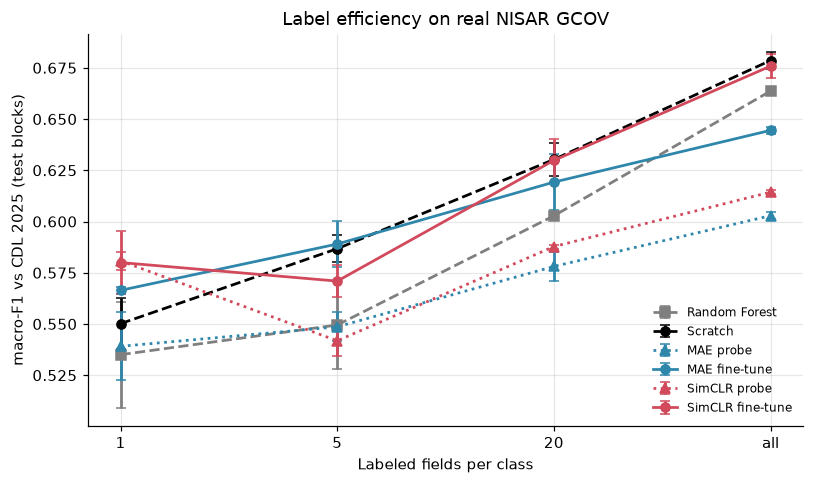

In [21]:
table = res.groupby(["method", "budget"], sort=False)["macroF1"].agg(["mean", "std"]).round(3).unstack("budget")
table = table.reindex(columns=[(m, str(b)) for m in ["mean", "std"] for b in BUDGETS])
display(table)

order = ["Random Forest", "Scratch", "MAE probe", "MAE fine-tune", "SimCLR probe", "SimCLR fine-tune"]
style = {"Random Forest": ("#7F7F7F", "s", "--"), "Scratch": ("#000000", "o", "--"),
         "MAE probe": ("#2E86AB", "^", ":"), "MAE fine-tune": ("#2E86AB", "o", "-"),
         "SimCLR probe": ("#D1495B", "^", ":"), "SimCLR fine-tune": ("#D1495B", "o", "-")}
fig, ax = plt.subplots(figsize=(7.5, 4.5))
xpos = np.arange(len(BUDGETS)); labels_b = [str(b) for b in BUDGETS]
for m in order:
    g = res[res.method == m].groupby("budget", sort=False)["macroF1"]
    mean = g.mean().reindex(labels_b); lo = g.min().reindex(labels_b); hi = g.max().reindex(labels_b)
    c, mk, ls = style[m]
    ax.errorbar(xpos, mean, yerr=[mean - lo, hi - mean], color=c, marker=mk, ls=ls, capsize=3, lw=1.8, label=m)
ax.set_xticks(xpos, labels_b)
ax.set_xlabel("Labeled fields per class"); ax.set_ylabel(f"macro-F1 vs CDL {CDL_YEAR} (test blocks)")
ax.set_title("Label efficiency on real NISAR GCOV")
ax.legend(frameon=False, fontsize=8, loc="lower right"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(OUT_DIR / "label_efficiency.png", dpi=150); plt.show()

**Reading the curve.** The gap between pretrained models and *Scratch* at 1 to 5 fields per class is the value of the unlabeled stack. The *linear probe* shows how much crop information the frozen embedding already holds. With many labels, methods usually converge, and a Random Forest on good temporal features is a strong baseline. Remember the ceiling: agreement with a 2025 reference cannot reach 100% for 2026 crops where rotation changed the field.


## Crop map of AOI-1 and validation against the 10 m CDL

The map uses the neural model trained with **20 labeled fields per class** that scored best on the *validation* blocks (the test blocks are not used to choose it), and the Random Forest trained on the same fields for comparison.

**Object-based voting.** Pixel maps carry residual speckle. The NISAR stack itself is segmented with GeoLattice `segment` (SLIC superpixels on the season mean of HH and HV and the HV standard deviation), and class probabilities are averaged inside each segment. Segments come from the radar data only, so the CDL boundaries do not leak into the map.


Selected on validation blocks: Scratch (val macro-F1 0.646)


Predicted 3,580,797 pixels in 15s


15,237 SLIC segments (3s)


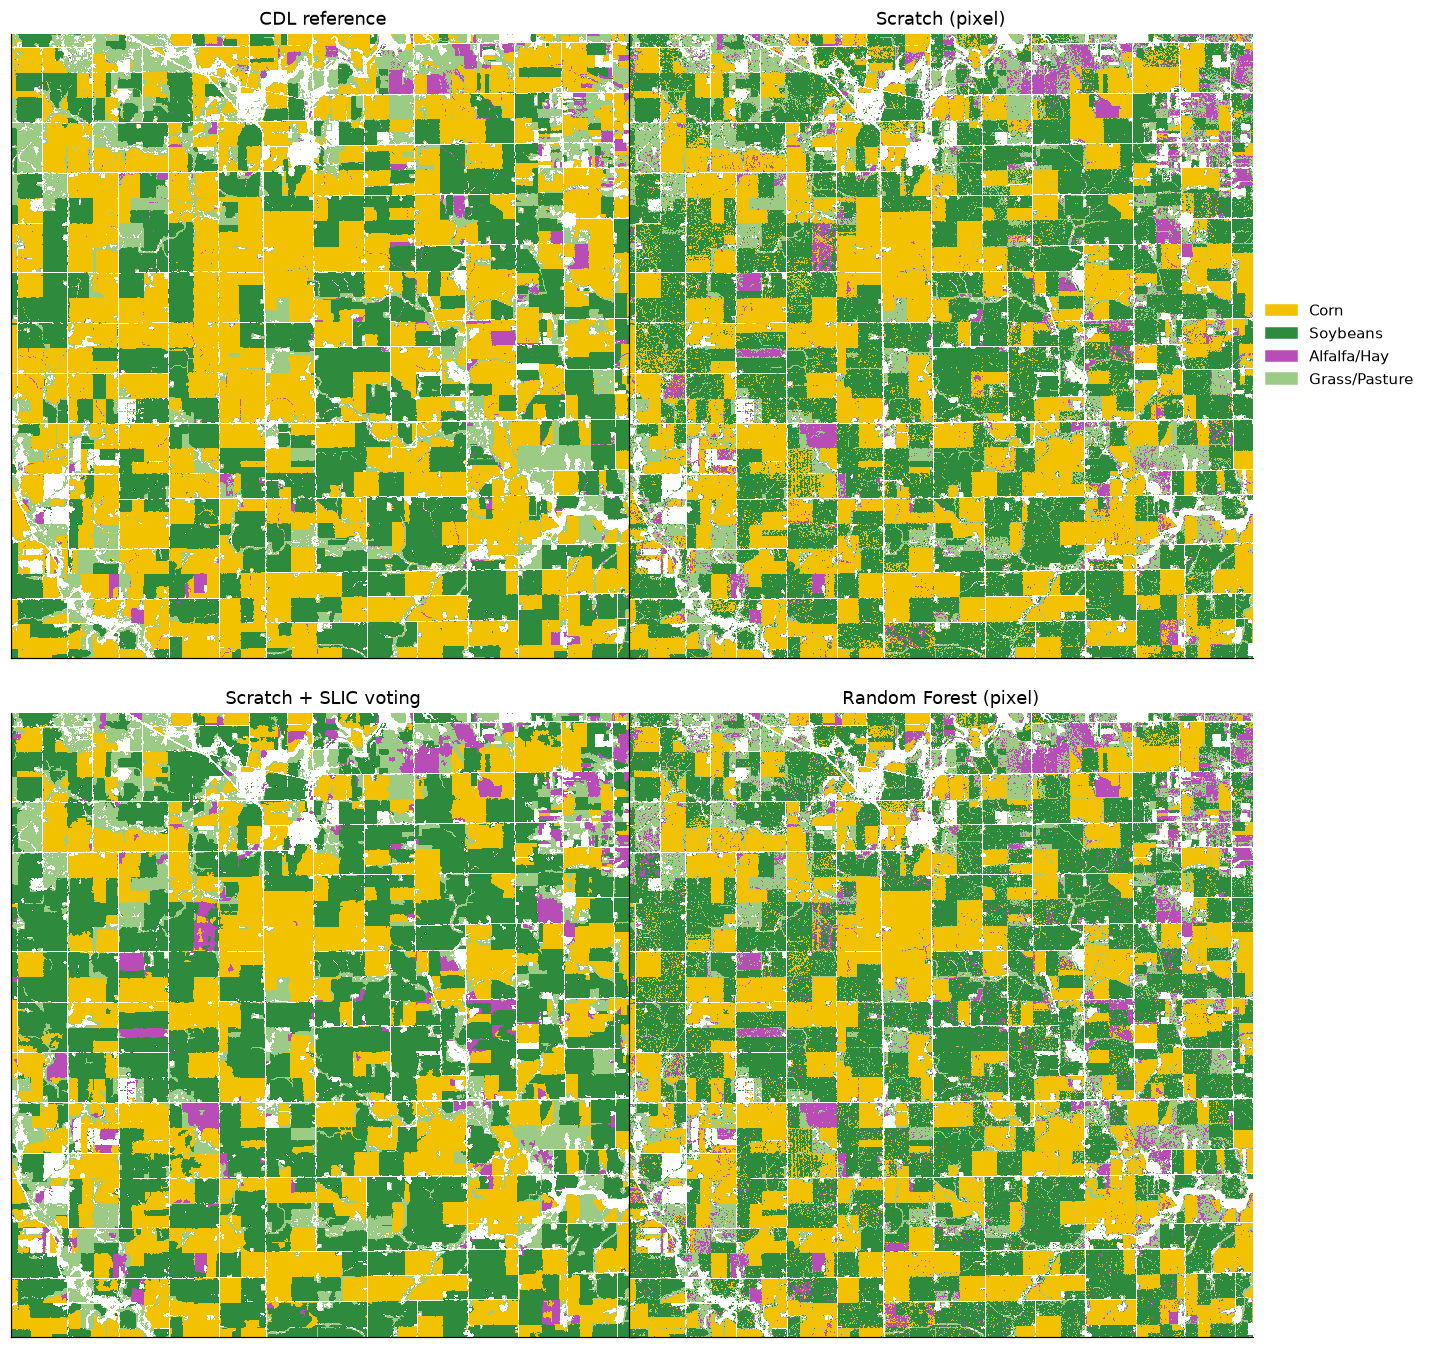

In [22]:
cands = [(name, trained[(name, "20")]) for name, _, _ in VARIANTS if (name, "20") in trained]
best_name, best = max(cands, key=lambda t: t[1].val_f1)
print("Selected on validation blocks:", best_name, f"(val macro-F1 {best.val_f1:.3f})")

t0 = time.time()
proba_A = predict(best, xA, dA, vA)
pred_pix = proba_A.argmax(1)
pred_rf = rf_models["20"].predict(HF_A)
print(f"Predicted {len(xA):,} pixels in {time.time() - t0:.0f}s")

# SLIC segments on season statistics of the filtered stack (GeoLattice OBIA).
dbc = to_db(cube)
seg_ds = xr.Dataset({"HH_mean": dbc.sel(pol="HH", drop=True).mean("time"),
                     "HV_mean": dbc.sel(pol="HV", drop=True).mean("time"),
                     "HV_std": dbc.sel(pol="HV", drop=True).std("time")})
n_seg = int(np.prod(cube.shape[-2:]) * POSTING ** 2 / (SEG_HA * 1e4))
t0 = time.time()
segments = segment(seg_ds, method="slic", n_segments=n_seg, compactness=0.1, sigma=1.0)
seg = np.asarray(segments.values).astype(np.int64)
print(f"{len(np.unique(seg)):,} SLIC segments ({time.time() - t0:.0f}s)")

seg_px = seg[metaA.row.values, metaA.col.values]
_, seg_idx = np.unique(seg_px, return_inverse=True)
seg_proba = np.stack([np.bincount(seg_idx, weights=proba_A[:, k]) for k in range(len(CLASSES))], 1)
pred_obj = seg_proba.argmax(1)[seg_idx]
conf = proba_A.max(1)

H, W = cube.shape[-2:]
def to_map(values, meta=metaA, fill=-1, dtype=np.int16):
    m = np.full((H, W), fill, dtype)
    m[meta.row.values, meta.col.values] = values
    return m

maps = {"CDL reference": y_maps[AOI1], f"{best_name} (pixel)": to_map(pred_pix),
        f"{best_name} + SLIC voting": to_map(pred_obj), "Random Forest (pixel)": to_map(pred_rf)}
fig, axes = plt.subplots(2, 2, figsize=(13, 12.5))
for ax, (title, m) in zip(axes.ravel(), maps.items()):
    ax.imshow(np.ma.masked_less(m, 0), cmap=CMAP, vmin=0, vmax=len(CLASSES) - 1, interpolation="nearest")
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])
axes[0, 1].legend(handles=HANDLES, loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False)
plt.tight_layout(); plt.savefig(OUT_DIR / "crop_maps_aoi1.png", dpi=150); plt.show()

### Wall-to-wall agreement on the held-out test blocks

Every cropland pixel of the test blocks is compared with the CDL, including field edges that were never used for training. GeoLattice `accuracy_report` returns overall accuracy, kappa, and per-class user's and producer's accuracy (confusion matrix rows = map, columns = reference).


In [23]:
test_all = np.flatnonzero(metaA.split == "test")
ref_test = yA[test_all]
rows_acc, reports = [], {}
for label, pred in [(f"{best_name} (pixel)", pred_pix), (f"{best_name} + SLIC voting", pred_obj),
                    ("Random Forest (pixel)", pred_rf)]:
    rep = accuracy_report(ref_test, pred[test_all], labels=list(range(len(CLASSES))))
    reports[label] = rep
    rows_acc.append({"map": label, "OA": rep["overall_accuracy"], "kappa": rep["kappa"],
                     "macroF1": np.nanmean(rep["per_class"]["f1"]),
                     "OA interior px": accuracy_score(yA[test_all][metaA.field.values[test_all] >= 0],
                                                      pred[test_all][metaA.field.values[test_all] >= 0])})
acc_table = pd.DataFrame(rows_acc).set_index("map").round(3)
acc_table.to_csv(OUT_DIR / "accuracy_test_blocks.csv")
print(f"Test blocks: {len(test_all):,} cropland pixels")
display(acc_table)

rep = reports[f"{best_name} + SLIC voting"]
pc = rep["per_class"].copy()
pc.index = CLASSES
pc["CDL national PA/UA (%)"] = [
    " / ".join(f"{v:.0f}" for v in CDL_NATIONAL_ACC[n]) if n in CDL_NATIONAL_ACC else
    {"Small grains": "85 / 83 (spring wheat)", "Alfalfa/Hay": "67 / 68 (alfalfa)"}.get(n, "–") for n in CLASSES]
display(pc.round(3))

Test blocks: 1,063,445 cropland pixels


,OA,kappa,macroF1,OA interior px
map,,,,
Scratch (pixel),0.719,0.571,0.610,0.752
Scratch + SLIC voting,0.733,0.586,0.640,0.768
Random Forest (pixel),0.698,0.544,0.588,0.730


,users_accuracy,producers_accuracy,f1,n_reference,CDL national PA/UA (%)
Corn,0.933,0.627,0.750,540210,92 / 91
Soybeans,0.629,0.918,0.747,355543,91 / 90
Alfalfa/Hay,0.239,0.472,0.318,25158,67 / 68 (alfalfa)
Grass/Pasture,0.776,0.718,0.746,142534,–


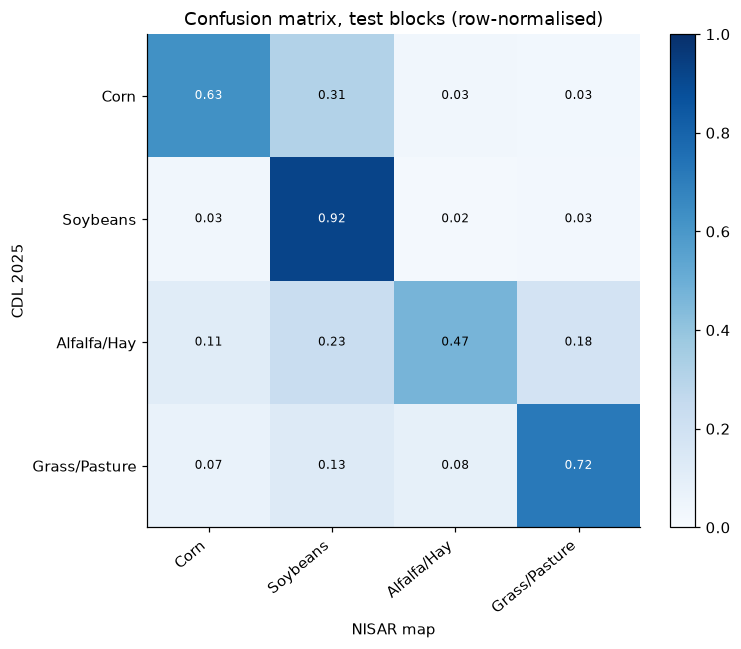

In [24]:
cm = rep["confusion_matrix"].to_numpy(float).T                     # rows = reference, cols = map
cmn = cm / np.clip(cm.sum(1, keepdims=True), 1, None)
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(CLASSES)), CLASSES, rotation=40, ha="right"); ax.set_yticks(range(len(CLASSES)), CLASSES)
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        ax.text(j, i, f"{cmn[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if cmn[i, j] > 0.5 else "black")
ax.set_xlabel("NISAR map"); ax.set_ylabel(f"CDL {CDL_YEAR}")
ax.set_title("Confusion matrix, test blocks (row-normalised)")
plt.colorbar(im, fraction=0.046); plt.tight_layout(); plt.savefig(OUT_DIR / "confusion_matrix.png", dpi=150); plt.show()

### Stratified random sample and area-adjusted accuracy (Olofsson et al. 2014)

Wall-to-wall agreement weights classes by their area and ignores how a map would be validated in practice. The good-practice design is a **stratified random sample** with the map classes as strata, here `N_PER_STRATUM` pixels per class drawn from the test blocks, with the CDL as the reference label. GeoLattice `olofsson` turns the sample confusion matrix and the mapped area of each stratum into area-weighted overall, user's and producer's accuracy with 95% confidence intervals, and an **error-adjusted area** for each class.


Sample: 1,600 pixels | area-weighted OA = 0.743 ± 0.025 (95% CI)


,map_area,adjusted_area,area_ci,CDL_area,users_accuracy,ua_ci,producers_accuracy,pa_ci
Corn,3631.0,5392.0,252.0,5402.0,0.955,0.020,0.643,0.029
Soybeans,5188.0,3505.0,255.0,3555.0,0.625,0.048,0.925,0.018
Alfalfa/Hay,496.0,315.0,89.0,252.0,0.238,0.042,0.374,0.111
Grass/Pasture,1319.0,1422.0,114.0,1425.0,0.815,0.038,0.756,0.055


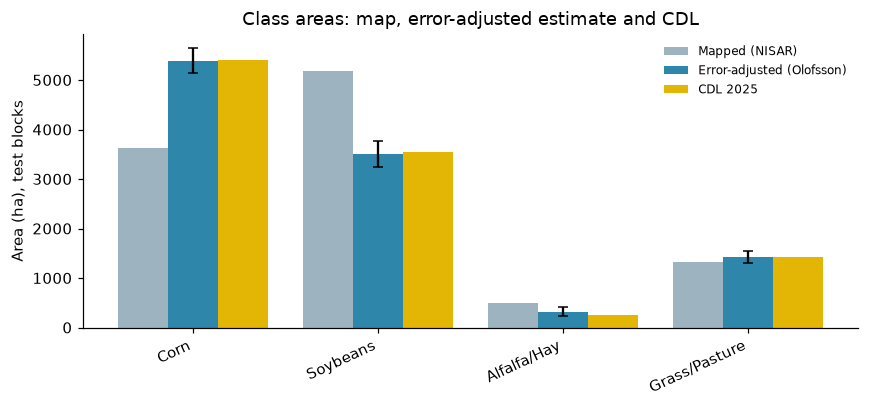

In [25]:
rng = np.random.default_rng(SEED)
pred_final = pred_obj
pop = test_all                                                     # population: cropland pixels of test blocks
map_counts = pd.Series(np.bincount(pred_final[pop], minlength=len(CLASSES)), index=range(len(CLASSES)))
sample = np.concatenate([rng.choice(pop[pred_final[pop] == k], min(N_PER_STRATUM, int(map_counts[k])), replace=False)
                         for k in range(len(CLASSES)) if map_counts[k] > 1])
cm_s = pg_confusion_matrix(yA[sample], pred_final[sample], labels=list(range(len(CLASSES))))
strata = [k for k in range(len(CLASSES)) if map_counts[k] > 1]
cm_s = cm_s.loc[strata, strata]
ol = olofsson(cm_s, {k: map_counts[k] for k in strata}, pixel_area=POSTING ** 2 / 1e4)   # hectares
tab = ol["table"].copy()
tab.index = [CLASSES[k] for k in strata]
tab["CDL_area"] = [(yA[pop] == k).sum() * POSTING ** 2 / 1e4 for k in strata]
tab = tab[["map_area", "adjusted_area", "area_ci", "CDL_area", "users_accuracy", "ua_ci", "producers_accuracy", "pa_ci"]]
print(f"Sample: {len(sample):,} pixels | area-weighted OA = {ol['overall_accuracy']:.3f} ± {ol['oa_ci']:.3f} (95% CI)")
display(tab.round({"map_area": 0, "adjusted_area": 0, "area_ci": 0, "CDL_area": 0, "users_accuracy": 3,
                   "ua_ci": 3, "producers_accuracy": 3, "pa_ci": 3}))
tab.to_csv(OUT_DIR / "olofsson_area_accuracy.csv")

fig, ax = plt.subplots(figsize=(8, 3.8))
xx = np.arange(len(tab)); w = 0.27
ax.bar(xx - w, tab.map_area, w, label="Mapped (NISAR)", color="#9DB4C0")
ax.bar(xx, tab.adjusted_area, w, yerr=tab.area_ci, capsize=3, label="Error-adjusted (Olofsson)", color="#2E86AB")
ax.bar(xx + w, tab.CDL_area, w, label=f"CDL {CDL_YEAR}", color="#E3B505")
ax.set_xticks(xx, tab.index, rotation=25, ha="right"); ax.set_ylabel("Area (ha), test blocks")
ax.legend(frameon=False, fontsize=8); ax.set_title("Class areas: map, error-adjusted estimate and CDL")
plt.tight_layout(); plt.show()

### Where the map and the CDL disagree

The agreement map shows *where* disagreement concentrates. Errors along field edges point to mixed pixels and small misregistration; whole-field disagreement between corn and soybean is the signature of rotation between 2025 and 2026 (or of an error in either product). Low model confidence is a useful flag for both.


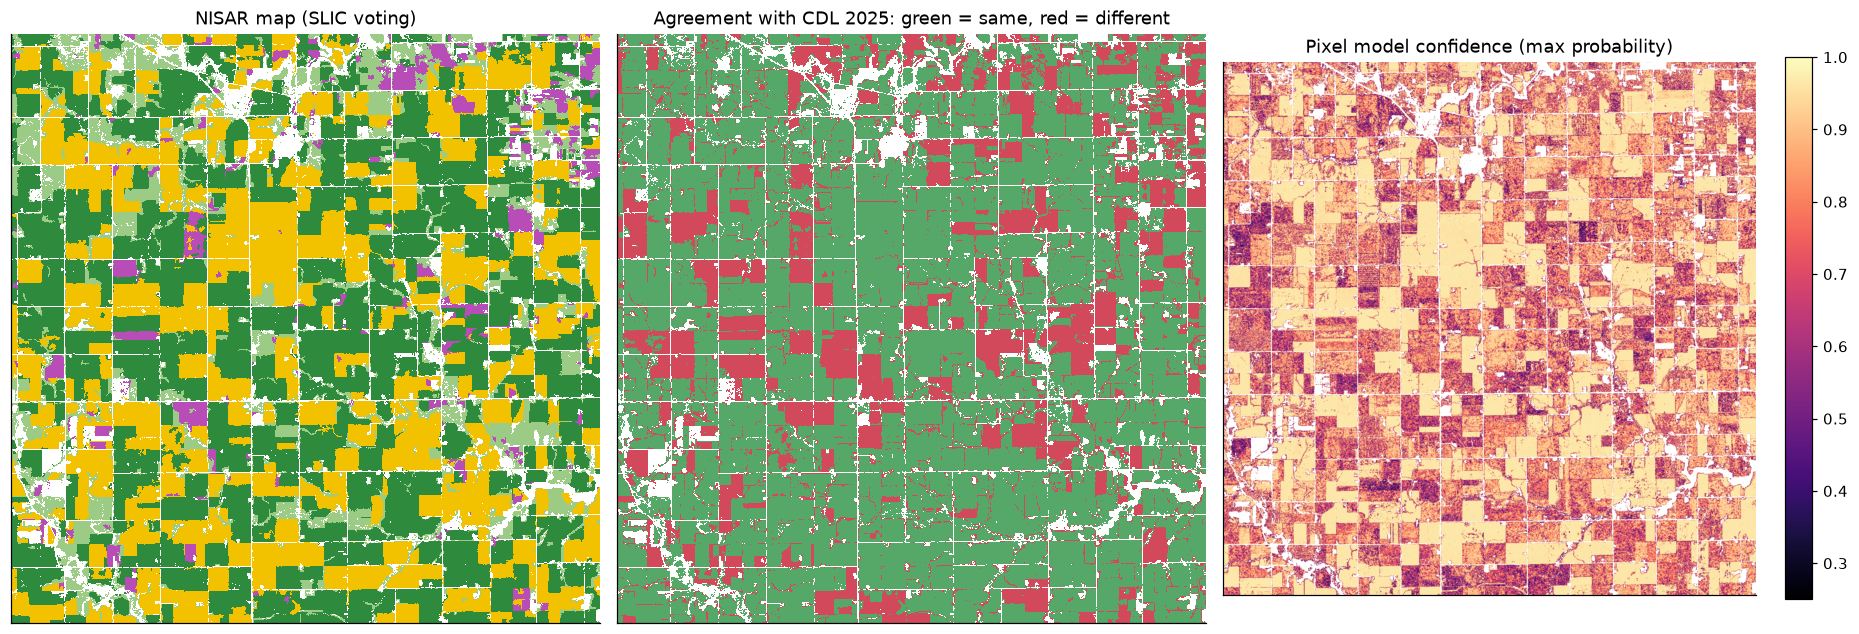

Disagreement on field-edge pixels: 0.449 | interior pixels: 0.217


In [26]:
agree = np.full((H, W), np.nan)
agree[metaA.row.values, metaA.col.values] = (pred_final == yA).astype(float)
conf_map = np.full((H, W), np.nan); conf_map[metaA.row.values, metaA.col.values] = conf
fig, axes = plt.subplots(1, 3, figsize=(17, 5.8))
axes[0].imshow(np.ma.masked_less(to_map(pred_final), 0), cmap=CMAP, vmin=0, vmax=len(CLASSES) - 1, interpolation="nearest")
axes[0].set_title("NISAR map (SLIC voting)")
axes[1].imshow(agree, cmap=ListedColormap(["#D1495B", "#55A868"]), vmin=0, vmax=1, interpolation="nearest")
axes[1].set_title(f"Agreement with CDL {CDL_YEAR}: green = same, red = different")
im = axes[2].imshow(conf_map, cmap="magma", vmin=1 / len(CLASSES), vmax=1)
axes[2].set_title("Pixel model confidence (max probability)"); plt.colorbar(im, ax=axes[2], fraction=0.046)
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.savefig(OUT_DIR / "agreement_aoi1.png", dpi=150); plt.show()

edge = metaA.field.values < 0
print(f"Disagreement on field-edge pixels: {1 - agree[metaA.row.values[edge], metaA.col.values[edge]].mean():.3f} | "
      f"interior pixels: {1 - agree[metaA.row.values[~edge], metaA.col.values[~edge]].mean():.3f}")

### How much disagreement is corn ↔ soybean?

If the corn and soybean classes are merged into one *Corn/Soy* class, overall agreement can only rise. The size of the jump measures how much of the remaining disagreement is corn/soybean confusion. In a region with a strong corn–soybean rotation, part of that confusion reflects real 2025 → 2026 changes rather than map errors; the 2026 CDL (or field data) is needed to separate the two.


In [27]:
if {"Corn", "Soybeans"} <= set(CLASSES):
    ic, isb = CLASSES.index("Corn"), CLASSES.index("Soybeans")
    def merge(a):
        a = a.copy(); a[a == isb] = ic; return a
    r_full = accuracy_score(ref_test, pred_final[test_all])
    r_merged = accuracy_score(merge(ref_test), merge(pred_final[test_all]))
    cs = ((ref_test == ic) & (pred_final[test_all] == isb)) | ((ref_test == isb) & (pred_final[test_all] == ic))
    print(f"Overall agreement: {r_full:.3f} with corn and soybean separate, {r_merged:.3f} merged")
    print(f"Corn<->soybean swaps are {cs.mean():.1%} of test pixels and "
          f"{cs.sum() / max(1, (ref_test != pred_final[test_all]).sum()):.0%} of all disagreement")
    # Whole-unit swaps: units where most pixels flipped corn<->soybean look like rotation, not noise.
    sw = pd.DataFrame({"field": metaA.field.values[test_all], "swap": cs})
    sw = sw[sw.field >= 0].groupby("field").swap.mean()
    print(f"Test units with >80% of pixels swapped corn<->soybean: {(sw > 0.8).sum()} of {len(sw)}")
else:
    print("Corn and soybean are not both present in this AOI.")

Overall agreement: 0.733 with corn and soybean separate, 0.902 merged
Corn<->soybean swaps are 16.9% of test pixels and 63% of all disagreement
Test units with >80% of pixels swapped corn<->soybean: 80 of 723


## Spatial transfer to an unlabeled AOI

AOI-2 lies elsewhere in the same frame and was never labeled; its pixels only entered the **unlabeled** pretraining pool. Each method is trained with 20 labeled fields per class from AOI-1 and applied to all AOI-2 cropland, then compared with the CDL there. This is the realistic case of mapping a new county with labels collected somewhere else.


OA        macroF1         kappa       
                   mean    std    mean    std   mean    std
method                                                     
Random Forest     0.758  0.003   0.586  0.003  0.602  0.005
Scratch           0.762  0.002   0.597  0.007  0.606  0.001
MAE fine-tune     0.772  0.003   0.599  0.003  0.622  0.005
SimCLR fine-tune  0.765  0.006   0.595  0.001  0.612  0.009

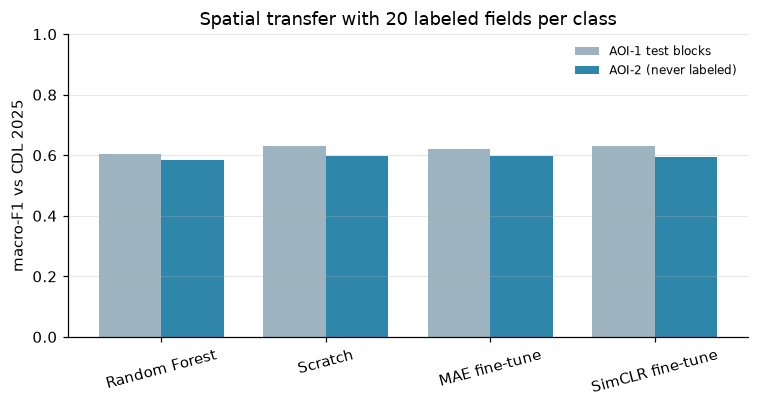

In [28]:
transfer = []
if TRANSFER_AOI and len(AOIS) > 1:
    AOI2 = AOIS[1]["name"]
    xB, dB_, vB, metaB = samples[AOI2]
    yB = metaB.y.values
    rngB = np.random.default_rng(SEED)
    evalB = rngB.choice(len(yB), min(len(yB), 100_000), replace=False)
    for s in SEEDS:
        idx = sample_label_budget(metaA, 20, seed=100 + s)
        rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=2, n_jobs=-1, class_weight="balanced",
                                    random_state=s).fit(HF_A[idx], yA[idx])
        transfer.append({"method": "Random Forest", "seed": s, **evaluate(yB[evalB], rf.predict(HF[AOI2][evalB]))})
        for name, init, mode in [("Scratch", "scratch", "full"), ("MAE fine-tune", "mae", "finetune"),
                                 ("SimCLR fine-tune", "simclr", "finetune")]:
            model = trained[(name, "20")] if s == 0 else train_classifier(init, mode, idx, xA, dA, vA, yA, idx_val, seed=s)
            pred = predict(model, xB[evalB], dB_[evalB], vB[evalB]).argmax(1)
            transfer.append({"method": name, "seed": s, **evaluate(yB[evalB], pred)})
    tr = pd.DataFrame(transfer)
    summary_tr = tr.groupby("method", sort=False)[["OA", "macroF1", "kappa"]].agg(["mean", "std"]).round(3)
    summary_tr.to_csv(OUT_DIR / "transfer_aoi2.csv")
    display(summary_tr)

    in_domain = res[res.budget == "20"].groupby("method")["macroF1"].mean()
    cross = tr.groupby("method")["macroF1"].mean()
    meths = ["Random Forest", "Scratch", "MAE fine-tune", "SimCLR fine-tune"]
    fig, ax = plt.subplots(figsize=(7, 3.8))
    w = 0.38; xx = np.arange(len(meths))
    ax.bar(xx - w / 2, [in_domain[m] for m in meths], w, label="AOI-1 test blocks", color="#9DB4C0")
    ax.bar(xx + w / 2, [cross[m] for m in meths], w, label="AOI-2 (never labeled)", color="#2E86AB")
    ax.set_xticks(xx, meths, rotation=15); ax.set_ylabel(f"macro-F1 vs CDL {CDL_YEAR}"); ax.set_ylim(0, 1)
    ax.set_title("Spatial transfer with 20 labeled fields per class")
    ax.legend(frameon=False, fontsize=8); ax.grid(axis="y", alpha=0.3)
    plt.tight_layout(); plt.savefig(OUT_DIR / "transfer_aoi2.png", dpi=150); plt.show()
else:
    print("TRANSFER_AOI is False or no second AOI was found.")

### What the encoders learned

A 2-D projection of pooled embeddings for AOI-1 test pixels, coloured by CDL class, for a random encoder and the MAE and SimCLR encoders **before any labels were used**, plus a k-NN check of how separable the classes are in each frozen embedding.


k-NN macro-F1 on frozen scratch  embeddings: 0.585


k-NN macro-F1 on frozen mae      embeddings: 0.601


k-NN macro-F1 on frozen simclr   embeddings: 0.630


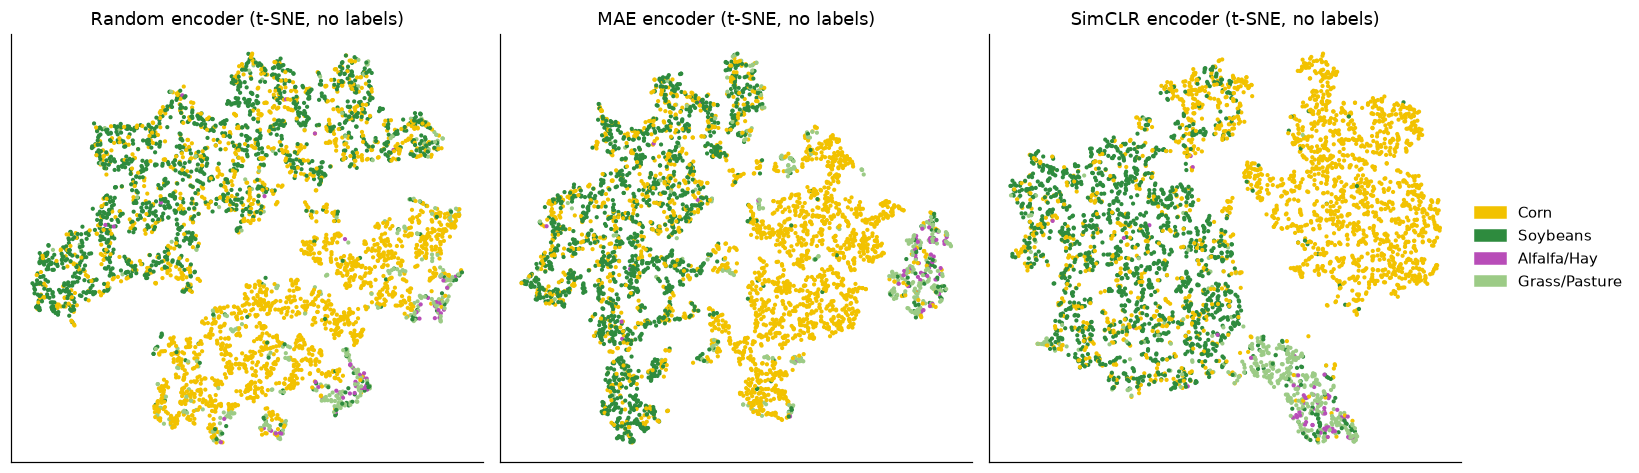

In [29]:
try:
    import umap
    reducer, proj_name = (lambda: umap.UMAP(n_neighbors=30, min_dist=0.3, random_state=SEED)), "UMAP"
except ImportError:
    from sklearn.manifold import TSNE
    reducer, proj_name = (lambda: TSNE(init="pca", random_state=SEED)), "t-SNE"
from sklearn.neighbors import KNeighborsClassifier

sub = np.random.default_rng(SEED).choice(idx_eval, min(4000, len(idx_eval)), replace=False)
tr_idx = sample_label_budget(metaA, "all", seed=0)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
for ax, init, title in zip(axes, ["scratch", "mae", "simclr"], ["Random encoder", "MAE encoder", "SimCLR encoder"]):
    torch.manual_seed(0)
    m = CropClassifier(make_encoder(init), len(CLASSES)).to(DEVICE)
    emb = predict(m, xA[sub], dA[sub], vA[sub], return_emb=True)
    p2 = reducer().fit_transform(emb)
    ax.scatter(p2[:, 0], p2[:, 1], c=yA[sub], cmap=CMAP, vmin=0, vmax=len(CLASSES) - 1, s=3)
    ax.set_title(f"{title} ({proj_name}, no labels)"); ax.set_xticks([]); ax.set_yticks([])
    etr = predict(m, xA[tr_idx], dA[tr_idx], vA[tr_idx], return_emb=True)
    knn = KNeighborsClassifier(15).fit(etr, yA[tr_idx])
    print(f"k-NN macro-F1 on frozen {init:8s} embeddings: "
          f"{f1_score(yA[idx_eval], knn.predict(predict(m, xA[idx_eval], dA[idx_eval], vA[idx_eval], return_emb=True)), average='macro'):.3f}")
axes[2].legend(handles=HANDLES, loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False)
plt.tight_layout(); plt.show()

## Saving outputs

Maps are written as Cloud-Optimised-style GeoTIFFs on the NISAR UTM grid (class codes follow `CLASSES`; 255 = not classified), together with the confidence and agreement layers, the CDL reference on the same grid, model weights and the class/normalisation configuration needed to apply the model to new GCOV scenes.


In [30]:
def save_tif(arr, path, dtype="uint8", nodata=255):
    a = np.where(np.isnan(arr) if np.issubdtype(np.asarray(arr).dtype, np.floating) else arr < 0, nodata, arr)
    with rasterio.open(path, "w", driver="GTiff", height=H, width=W, count=1, dtype=dtype, crs=STACK_CRS,
                       transform=AOIS[0]["transform"], nodata=nodata, compress="deflate", tiled=True) as dst:
        dst.write(a.astype(dtype), 1)
    return path.name

written = [
    save_tif(to_map(pred_obj), OUT_DIR / "crop_map_aoi1_slic.tif"),
    save_tif(to_map(pred_pix), OUT_DIR / "crop_map_aoi1_pixel.tif"),
    save_tif(to_map(pred_rf), OUT_DIR / "crop_map_aoi1_rf.tif"),
    save_tif(y_maps[AOI1], OUT_DIR / f"cdl{CDL_YEAR}_classes_aoi1.tif"),
    save_tif(conf_map.astype("float32"), OUT_DIR / "confidence_aoi1.tif", dtype="float32", nodata=-1),
    save_tif(np.where(np.isnan(agree), 255, agree), OUT_DIR / "agreement_aoi1.tif"),
]
torch.save(best.state_dict(), OUT_DIR / "classifier_best_20fields.pt")
json.dump({"classes": CLASSES, "colors": COLORS, "cdl_groups": {k: v for k, v in GROUPS.items() if k in CLASSES},
           "channels": CHANNELS, "feat_mean": FEAT_MEAN.tolist(), "feat_std": FEAT_STD.tolist(),
           "model": best_name, "stack": {"track": int(key[0]), "direction": key[1], "frame": int(key[2]),
                                         "dates": [d.strftime("%Y-%m-%d") for d in DATES], "crs": STACK_CRS},
           "aois": [{"name": a["name"], "bounds": a["bounds"]} for a in AOIS], "cdl_year": CDL_YEAR},
          open(OUT_DIR / "model_config.json", "w"), indent=2)
print("Wrote:", written)
print(sorted(p.name for p in OUT_DIR.iterdir()))

Wrote: ['crop_map_aoi1_slic.tif', 'crop_map_aoi1_pixel.tif', 'crop_map_aoi1_rf.tif', 'cdl2025_classes_aoi1.tif', 'confidence_aoi1.tif', 'agreement_aoi1.tif']
['accuracy_test_blocks.csv', 'agreement_aoi1.png', 'agreement_aoi1.tif', 'aoi1_nisar_vs_cdl.png', 'aoi1_quicklooks.png', 'cdl2025_classes_aoi1.tif', 'class_signatures.png', 'classifier_best_20fields.pt', 'confidence_aoi1.tif', 'confusion_matrix.png', 'crop_map_aoi1_pixel.tif', 'crop_map_aoi1_rf.tif', 'crop_map_aoi1_slic.tif', 'crop_maps_aoi1.png', 'encoder_mae.pt', 'encoder_simclr.pt', 'frame_overview.png', 'label_efficiency.png', 'label_efficiency_results.csv', 'model_config.json', 'olofsson_area_accuracy.csv', 'transfer_aoi2.csv', 'transfer_aoi2.png']


## Limitations and next steps

1. **Use the 2026 CDL when it is released** (NASS usually publishes in January–February). Change `CDL_PATH` and `CDL_YEAR` and rerun; the rotation diagnostic in Section 12.4 shows how much this matters for your AOI.
2. **Add early-season passes.** The archive used here starts on 23 July. Passes from May–June capture emergence and give much better separation of small grains, hay and late-planted crops.
3. **Add the ascending track** over the same area as extra tokens with their own DOY (and an incidence-angle channel). Do not mix tracks in one stack without that.
4. **Use real parcels.** Replace the CDL-derived units with Common Land Unit or field-boundary polygons (for example from the SAM-based delineation in Part VI) for training splits and object voting.
5. **Scale pretraining**: sample a few million pixels across all frames and seasons, `d_model = 128`, 4 layers, 50+ MAE epochs on a GPU.
6. **Watch calibration and RFI**: keep one product release per stack, and check each date's quick-look; L-band RFI shows as bright streaks that the mask may not flag.

### Exercises

1. Change the MAE mask ratio to 0.3 and 0.7. How does the label-efficiency curve change with only six dates?
2. Replace the Quegan filter with single-date `speckle.refined_lee` and compare pixel-level and SLIC-voting accuracy.
3. Merge *Grass/Pasture* and *Alfalfa/Hay* (CDL accuracy for other hay is low). Does map–CDL agreement improve, and is that a better or only an easier map?
4. Set `AOI_CENTER_LONLAT` to an area dominated by small grains and sunflower and repeat Sections 11–12.
5. Train with the 2025 CDL and test on only those units that kept the same crop in 2024 and 2025 (download the 2024 CDL): a rough way to reduce rotation noise in the reference.

## References

- Boryan, C., Yang, Z., Mueller, R., & Craig, M. (2011). Monitoring US agriculture: the US Department of Agriculture, National Agricultural Statistics Service, Cropland Data Layer Program. *Geocarto International*, 26(5), 341–358.
- Chen, T., Kornblith, S., Norouzi, M., & Hinton, G. (2020). A simple framework for contrastive learning of visual representations (SimCLR). *ICML*.
- He, K. et al. (2022). Masked autoencoders are scalable vision learners. *CVPR*.
- Li, Z., Mueller, R., Yang, Z., Johnson, D., & Willis, P. (2024). Cloud-powered agricultural mapping: a revolution toward 10 m resolution Cropland Data Layers. *IGARSS 2024*, 4081–4084.
- NASA/JPL & ISRO. *NISAR Science Users' Handbook*; ASF DAAC. *NISAR Level-2 GCOV Product Specification*.
- Olofsson, P., Foody, G. M., Herold, M., Stehman, S. V., Woodcock, C. E., & Wulder, M. A. (2014). Good practices for estimating area and assessing accuracy of land change. *Remote Sensing of Environment*, 148, 42–57.
- Quegan, S., & Yu, J. J. (2001). Filtering of multichannel SAR images. *IEEE TGRS*, 39(11), 2373–2379.
- Garnot, V. S. F. et al. (2020). Satellite image time series classification with pixel-set encoders and temporal self-attention. *CVPR*.
- Tseng, G. et al. (2023). Lightweight, pre-trained transformers for remote sensing timeseries (Presto). *arXiv:2304.14065*.
- USDA NASS (2026). *2025 Cropland Data Layer metadata* (FGDC), statewide agricultural accuracy report.
